# Stage 4 — Camera–LiDAR Sensor Fusion

## Objective

Build an initial object-level fusion demonstration using the DENSE / Seeing Through Fog dataset.

The pipeline combines:

1. **Camera perception:** YOLO detections in the rectified RGB image.
2. **LiDAR geometry:** original 3D LiDAR returns from the matching `.bin` scan.
3. **Geometric association:** project LiDAR points into the camera image and associate projected points with 2D detection boxes.
4. **Object-level output:** report a robust LiDAR range estimate for each detection with sufficient associated points.

This is an initial geometric late-fusion baseline. It is **not** a learned fusion network, a 3D object detector, or a validated production distance-estimation system.

### Important interpretation notes

- The RGB image and LiDAR scan must have exactly matching frame IDs.
- The camera images are already rectified. We therefore use `VTC = P @ T_camera_lidar`; we do **not** apply the camera rectification matrix `R` again.
- The raw `.bin` layout is treated as candidate XYZ plus two additional fields, consistent with the previous exploratory inspection.
- LiDAR range is calculated from the original LiDAR XYZ coordinates. Calibration translation units are assumed to be metres, as in Stage 3B.
- A 2D box can contain background points and points from neighbouring objects. The median range is therefore an initial robust estimate, not guaranteed object ground truth.

## 1. Environment and project paths

Run this notebook from the project root, or let the cell locate the known WSL project directory. No model training is performed here.

In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.spatial.transform import Rotation
from ultralytics import YOLO
import torch

# Locate project root
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "dataset" / "seeing_through_fog").exists():
    candidates = [
        Path("/home/maritza/projects/autonomous_vehicle"),
        Path.cwd() / "autonomous_vehicle",
    ]
    PROJECT_DIR = next(
        (p for p in candidates if (p / "dataset" / "seeing_through_fog").exists()),
        None
    )

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate the project root containing dataset/seeing_through_fog."
    )

DATASET_DIR = PROJECT_DIR / "dataset" / "seeing_through_fog"
EXTRACTED_DIR = DATASET_DIR / "extracted"

CAMERA_DIR = EXTRACTED_DIR / "cam_stereo_left_lut"
LIDAR_DIR = EXTRACTED_DIR / "lidar_hdl64_last"

CALIBRATION_DIR = DATASET_DIR / "downloads" / "calibration"
TF_PATH = CALIBRATION_DIR / "calib_tf_tree_full.json"
CAMERA_CALIBRATION_PATH = CALIBRATION_DIR / "calib_cam_stereo_left.json"

GENERALIST_PATH = PROJECT_DIR / "models" / "yolov8n_rgb" / "best.pt"

for label, path in {
    "Project": PROJECT_DIR,
    "Camera images": CAMERA_DIR,
    "Original LiDAR": LIDAR_DIR,
    "Transform calibration": TF_PATH,
    "Camera calibration": CAMERA_CALIBRATION_PATH,
    "Generalist YOLO weights": GENERALIST_PATH,
}.items():
    print(f"{label}: {path} | exists={path.exists()}")

required_paths = [
    CAMERA_DIR, LIDAR_DIR, TF_PATH, CAMERA_CALIBRATION_PATH, GENERALIST_PATH
]
missing_paths = [str(p) for p in required_paths if not p.exists()]
if missing_paths:
    raise FileNotFoundError("Missing required paths:\n" + "\n".join(missing_paths))

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("\nInference device:", DEVICE)

Project: /home/maritza/projects/autonomous_vehicle | exists=True
Camera images: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/cam_stereo_left_lut | exists=True
Original LiDAR: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/extracted/lidar_hdl64_last | exists=True
Transform calibration: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/downloads/calibration/calib_tf_tree_full.json | exists=True
Camera calibration: /home/maritza/projects/autonomous_vehicle/dataset/seeing_through_fog/downloads/calibration/calib_cam_stereo_left.json | exists=True
Generalist YOLO weights: /home/maritza/projects/autonomous_vehicle/models/yolov8n_rgb/best.pt | exists=True

Inference device: 0


## 2. Load the camera–LiDAR calibration

We reproduce the Stage 3B transform:

\[
T_{camera\leftarrow lidar}
=
T_{body\leftarrow camera}^{-1}
T_{body\leftarrow lidar}
\]

The rectified projection matrix is then composed as:

\[
VTC = P\,T_{camera\leftarrow lidar}
\]

In [2]:
with open(TF_PATH, "r") as f:
    tf_data = json.load(f)

with open(CAMERA_CALIBRATION_PATH, "r") as f:
    camera_calibration = json.load(f)

def transform_to_matrix(translation, quaternion):
    """Build a 4x4 transform using quaternion order [x, y, z, w]."""
    q = [
        quaternion["x"],
        quaternion["y"],
        quaternion["z"],
        quaternion["w"],
    ]
    T = np.eye(4)
    T[:3, :3] = Rotation.from_quat(q).as_matrix()
    T[:3, 3] = [
        translation["x"],
        translation["y"],
        translation["z"],
    ]
    return T

lidar_entry = next(
    e for e in tf_data
    if e["child_frame_id"] == "lidar_hdl64_s3_roof"
)
camera_entry = next(
    e for e in tf_data
    if e["child_frame_id"] == "cam_stereo_left_optical"
)

T_body_lidar = transform_to_matrix(
    lidar_entry["transform"]["translation"],
    lidar_entry["transform"]["rotation"],
)
T_body_camera = transform_to_matrix(
    camera_entry["transform"]["translation"],
    camera_entry["transform"]["rotation"],
)

T_camera_lidar = np.linalg.inv(T_body_camera) @ T_body_lidar
P = np.asarray(camera_calibration["P"], dtype=float).reshape(3, 4)

# P is already the rectified projection matrix for the rectified RGB images.
VTC = P @ T_camera_lidar

print("T_camera_lidar:\n", np.round(T_camera_lidar, 6))
print("\nP:\n", np.round(P, 6))
print("\nVTC:\n", np.round(VTC, 6))

T_camera_lidar:
 [[   0.008166    -0.99996   -0.001533    0.087497]
 [  -0.007155    0.001475    -0.99997     -0.4164]
 [    0.99994    0.008176   -0.007143    -0.69556]
 [          0           0           0           1]]

P:
 [[     2355.7           0      988.14           0]
 [          0      2355.7      508.05           0]
 [          0           0           1           0]]

VTC:
 [[     1007.3     -2347.6     -10.671     -481.19]
 [     491.17      7.6288     -2359.3     -1334.3]
 [    0.99994    0.008176   -0.007143    -0.69556]]


## 3. Select and verify a synchronized frame

We start with the frame already inspected during Stage 3B. This avoids introducing a new frame-pairing variable into the first fusion demonstration.

In [3]:
FRAME_ID = "2019-09-11_16-39-41_01770"

rgb_matches = list(CAMERA_DIR.rglob(f"{FRAME_ID}.png"))
lidar_matches = list(LIDAR_DIR.rglob(f"{FRAME_ID}.bin"))

assert len(rgb_matches) == 1, (
    f"Expected one RGB image for {FRAME_ID}; found {len(rgb_matches)}"
)
assert len(lidar_matches) == 1, (
    f"Expected one LiDAR scan for {FRAME_ID}; found {len(lidar_matches)}"
)

RGB_PATH = rgb_matches[0]
LIDAR_PATH = lidar_matches[0]

rgb = np.asarray(Image.open(RGB_PATH).convert("RGB"))
raw_lidar = np.fromfile(LIDAR_PATH, dtype=np.float32)

if raw_lidar.size % 5 != 0:
    raise ValueError(
        f"Unexpected LiDAR binary size: {raw_lidar.size} float values; "
        "expected a multiple of 5."
    )

lidar_records = raw_lidar.reshape(-1, 5)
xyz_lidar = lidar_records[:, :3]

print("Frame ID:", FRAME_ID)
print("RGB:", RGB_PATH.name, rgb.shape)
print("LiDAR:", LIDAR_PATH.name)
print("LiDAR records:", len(lidar_records))
print("RGB/LiDAR frame match:", RGB_PATH.stem == LIDAR_PATH.stem)

assert RGB_PATH.stem == LIDAR_PATH.stem

Frame ID: 2019-09-11_16-39-41_01770
RGB: 2019-09-11_16-39-41_01770.png (1024, 1920, 3)
LiDAR: 2019-09-11_16-39-41_01770.bin
LiDAR records: 55602
RGB/LiDAR frame match: True


## 4. Load the pretrained generalist YOLO model and detect objects

We use the existing generalist model from Stage 2. The confidence threshold is fixed at 0.25 for this initial demonstration.

In [4]:
generalist_model = YOLO(str(GENERALIST_PATH))

CONFIDENCE_THRESHOLD = 0.25
IMAGE_SIZE = 640

yolo_result = generalist_model.predict(
    source=rgb,
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    device=DEVICE,
    verbose=False,
)[0]

detections = []

if yolo_result.boxes is not None:
    for box in yolo_result.boxes:
        xyxy = box.xyxy[0].detach().cpu().numpy().astype(float)
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())

        class_name = (
            generalist_model.names[class_id]
            if isinstance(generalist_model.names, dict)
            else generalist_model.names[class_id]
        )

        detections.append({
            "class_id": class_id,
            "class_name": str(class_name),
            "confidence": confidence,
            "xyxy": xyxy,
        })

print("YOLO detections:", len(detections))
for i, det in enumerate(detections[:20]):
    print(
        f"{i:02d} | {det['class_name']} | "
        f"confidence={det['confidence']:.3f} | "
        f"box={np.round(det['xyxy'], 1)}"
    )

YOLO detections: 1
00 | PassengerCar | confidence=0.877 | box=[      904.2       550.7         977       609.3]


## 5. Project the original LiDAR points into the rectified RGB image

The projection follows the validated Stage 3B procedure:

- candidate forward points: LiDAR `x > 2.5`;
- homogeneous transformation and projection with `VTC`;
- positive projected depth;
- image-boundary filtering;
- integer pixel conversion by truncation (`astype(np.int32)`), matching the Princeton implementation.

We preserve the index of each original LiDAR return so that image pixels remain linked to their original 3D coordinates.

In [5]:
def project_lidar_points(xyz, vtc, image_shape, min_lidar_x=2.5):
    """
    Project LiDAR XYZ points into a rectified camera image.

    Returns projected pixels, camera depth, original LiDAR range,
    and original point indices for traceable object association.
    """
    height, width = image_shape[:2]

    original_indices = np.arange(len(xyz))
    forward_mask = xyz[:, 0] > min_lidar_x

    xyz_forward = xyz[forward_mask]
    forward_indices = original_indices[forward_mask]

    xyz_h = np.column_stack([
        xyz_forward,
        np.ones(len(xyz_forward), dtype=float),
    ])

    projected_h = (vtc @ xyz_h.T).T
    projected_depth = projected_h[:, 2]

    positive_depth = projected_depth > 0

    projected_h = projected_h[positive_depth]
    xyz_positive = xyz_forward[positive_depth]
    indices_positive = forward_indices[positive_depth]
    camera_depth = projected_depth[positive_depth]

    u_float = projected_h[:, 0] / camera_depth
    v_float = projected_h[:, 1] / camera_depth

    inside = (
        (u_float >= 0) & (u_float < width) &
        (v_float >= 0) & (v_float < height)
    )

    u = u_float[inside].astype(np.int32)
    v = v_float[inside].astype(np.int32)

    xyz_lidar_valid = xyz_positive[inside]
    original_point_indices = indices_positive[inside]
    camera_depth_valid = camera_depth[inside]

    # Euclidean range from the LiDAR origin, based on original XYZ.
    lidar_range = np.linalg.norm(xyz_lidar_valid, axis=1)

    return {
        "u": u,
        "v": v,
        "xyz_lidar": xyz_lidar_valid,
        "original_indices": original_point_indices,
        "camera_depth": camera_depth_valid,
        "lidar_range": lidar_range,
        "n_input": len(xyz),
        "n_forward": len(xyz_forward),
        "n_projected": len(u),
    }


projection = project_lidar_points(
    xyz=xyz_lidar,
    vtc=VTC,
    image_shape=rgb.shape,
)

print("Input LiDAR points:", projection["n_input"])
print("After x > 2.5 m filter:", projection["n_forward"])
print("Projected inside image:", projection["n_projected"])

Input LiDAR points: 55602
After x > 2.5 m filter: 20026
Projected inside image: 4114


## 6. Visualize the camera image and projected LiDAR

The colour map represents Euclidean range calculated from the original LiDAR XYZ coordinates. The projection itself uses camera depth for perspective division; these are related but distinct quantities.

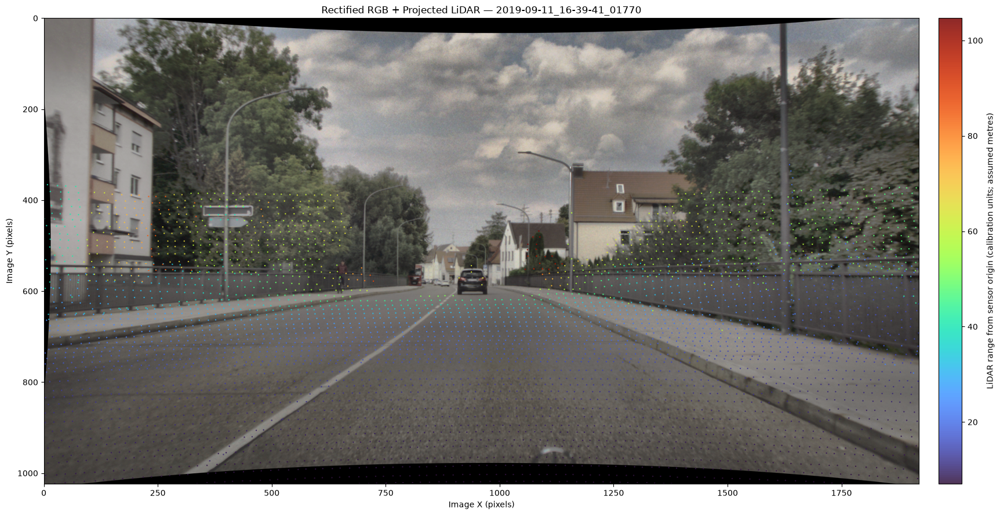

In [6]:
fig, ax = plt.subplots(figsize=(18, 9))
ax.imshow(rgb)

scatter = ax.scatter(
    projection["u"],
    projection["v"],
    c=projection["lidar_range"],
    cmap="turbo",
    s=3,
    alpha=0.85,
    linewidths=0,
)

cbar = plt.colorbar(scatter, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("LiDAR range from sensor origin (calibration units; assumed metres)")

ax.set_title(f"Rectified RGB + Projected LiDAR — {FRAME_ID}")
ax.set_xlim(0, rgb.shape[1])
ax.set_ylim(rgb.shape[0], 0)
ax.set_xlabel("Image X (pixels)")
ax.set_ylabel("Image Y (pixels)")
plt.tight_layout()
plt.show()

## 7. Associate projected LiDAR points with YOLO bounding boxes

For each 2D detection, we select projected LiDAR returns whose image pixels fall inside that box. We report:

- number of associated projected returns;
- median LiDAR range;
- interquartile range (25th–75th percentile).

The median is used as a robust initial summary. This association is purely 2D geometric containment: it does not yet separate foreground object points from background points within the same box.

In [7]:
def associate_lidar_with_detections(detections, projection, min_points=3):
    associations = []

    u = projection["u"]
    v = projection["v"]
    ranges = projection["lidar_range"]
    original_indices = projection["original_indices"]

    for detection_id, det in enumerate(detections):
        x1, y1, x2, y2 = det["xyxy"]

        inside_box = (
            (u >= x1) & (u < x2) &
            (v >= y1) & (v < y2)
        )

        point_ranges = ranges[inside_box]
        point_indices = original_indices[inside_box]

        if len(point_ranges) >= min_points:
            median_range = float(np.median(point_ranges))
            q25, q75 = np.percentile(point_ranges, [25, 75])
            status = "estimated"
        else:
            median_range = np.nan
            q25, q75 = np.nan, np.nan
            status = "insufficient_points"

        associations.append({
            "detection_id": detection_id,
            "class_name": det["class_name"],
            "confidence": det["confidence"],
            "bbox_xyxy": det["xyxy"],
            "n_lidar_points": int(len(point_ranges)),
            "median_lidar_range": median_range,
            "range_q25": float(q25),
            "range_q75": float(q75),
            "status": status,
            "associated_original_indices": point_indices,
        })

    return associations


associations = associate_lidar_with_detections(
    detections,
    projection,
    min_points=3,
)

for item in associations:
    if item["status"] == "estimated":
        print(
            f"{item['detection_id']:02d} | {item['class_name']:<18} | "
            f"YOLO={item['confidence']:.2f} | "
            f"LiDAR points={item['n_lidar_points']:4d} | "
            f"median range={item['median_lidar_range']:.2f} | "
            f"IQR=[{item['range_q25']:.2f}, {item['range_q75']:.2f}]"
        )
    else:
        print(
            f"{item['detection_id']:02d} | {item['class_name']:<18} | "
            f"YOLO={item['confidence']:.2f} | "
            f"LiDAR points={item['n_lidar_points']:4d} | "
            "No reliable range estimate (too few points)"
        )

00 | PassengerCar       | YOLO=0.88 | LiDAR points=   4 | median range=63.71 | IQR=[63.69, 63.75]


## 8. Final fusion visualization

Bounding boxes are labelled with the YOLO class, confidence, and the median associated LiDAR range when enough projected returns are available.

This is the principal qualitative result for the initial fusion baseline.

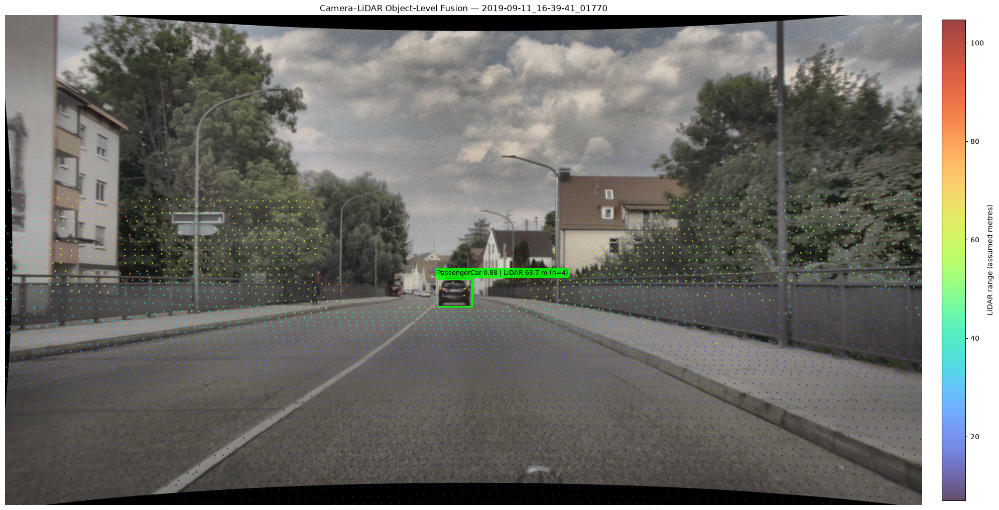

In [8]:
fig, ax = plt.subplots(figsize=(20, 11))
ax.imshow(rgb)

# LiDAR points coloured by range
scatter = ax.scatter(
    projection["u"],
    projection["v"],
    c=projection["lidar_range"],
    cmap="turbo",
    s=5,
    alpha=0.75,
    linewidths=0,
    label="Projected LiDAR",
)

cbar = plt.colorbar(scatter, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("LiDAR range (assumed metres)")

for item in associations:
    x1, y1, x2, y2 = item["bbox_xyxy"]

    color = "lime" if item["status"] == "estimated" else "orange"

    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor=color,
        linewidth=2,
    )
    ax.add_patch(rect)

    if item["status"] == "estimated":
        label = (
            f"{item['class_name']} {item['confidence']:.2f} | "
            f"LiDAR {item['median_lidar_range']:.1f} m "
            f"(n={item['n_lidar_points']})"
        )
    else:
        label = (
            f"{item['class_name']} {item['confidence']:.2f} | "
            f"LiDAR n={item['n_lidar_points']} (insufficient)"
        )

    ax.text(
        x1,
        max(0, y1 - 8),
        label,
        color="black",
        fontsize=9,
        bbox=dict(facecolor=color, alpha=0.85, edgecolor="none", pad=2),
    )

ax.set_title(f"Camera–LiDAR Object-Level Fusion — {FRAME_ID}")
ax.set_xlim(0, rgb.shape[1])
ax.set_ylim(rgb.shape[0], 0)
ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Tabular fused detections

This table is a compact object-level output that can be saved, inspected, and discussed independently of the visualization.

In [9]:
import pandas as pd

fusion_table = pd.DataFrame([
    {
        "detection_id": a["detection_id"],
        "class": a["class_name"],
        "yolo_confidence": a["confidence"],
        "lidar_points_in_box": a["n_lidar_points"],
        "median_lidar_range": a["median_lidar_range"],
        "range_q25": a["range_q25"],
        "range_q75": a["range_q75"],
        "range_status": a["status"],
    }
    for a in associations
])

display(fusion_table.round(3))

,detection_id,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,0,PassengerCar,0.877,4,63.707,63.685,63.751,estimated


## 10. Save the demonstration output

The notebook saves the fusion visualization and the fused-detection table under `outputs/stage4_camera_lidar_fusion/`.

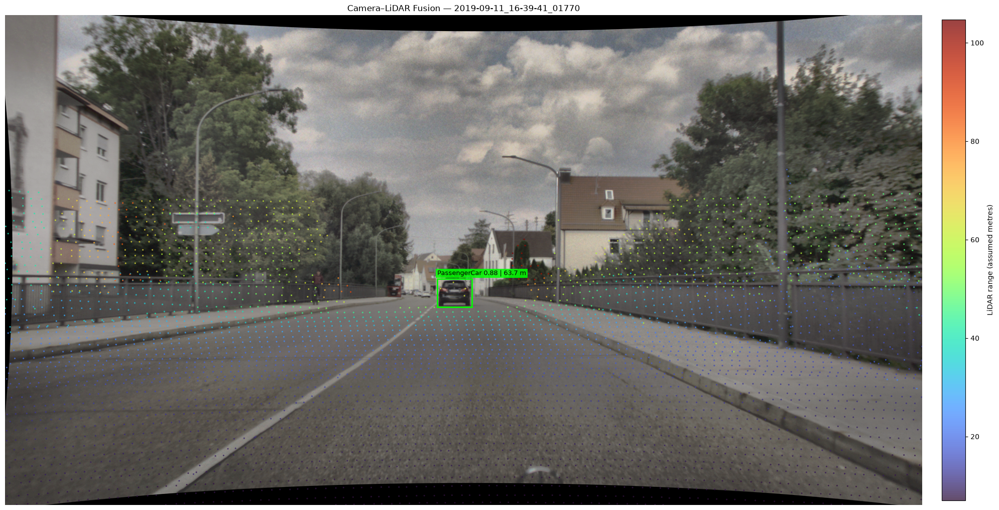

Saved visualization: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/2019-09-11_16-39-41_01770_camera_lidar_fusion.png
Saved fusion table: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/2019-09-11_16-39-41_01770_fused_detections.csv


In [10]:
OUTPUT_DIR = PROJECT_DIR / "outputs" / "stage4_camera_lidar_fusion"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

image_output_path = OUTPUT_DIR / f"{FRAME_ID}_camera_lidar_fusion.png"
table_output_path = OUTPUT_DIR / f"{FRAME_ID}_fused_detections.csv"

fig, ax = plt.subplots(figsize=(20, 11))
ax.imshow(rgb)

scatter = ax.scatter(
    projection["u"],
    projection["v"],
    c=projection["lidar_range"],
    cmap="turbo",
    s=5,
    alpha=0.75,
    linewidths=0,
)
plt.colorbar(scatter, ax=ax, fraction=0.025, pad=0.02,
             label="LiDAR range (assumed metres)")

for item in associations:
    x1, y1, x2, y2 = item["bbox_xyxy"]
    color = "lime" if item["status"] == "estimated" else "orange"

    ax.add_patch(plt.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        fill=False, edgecolor=color, linewidth=2
    ))

    if item["status"] == "estimated":
        label = (
            f"{item['class_name']} {item['confidence']:.2f} | "
            f"{item['median_lidar_range']:.1f} m"
        )
    else:
        label = f"{item['class_name']} | no range"

    ax.text(
        x1, max(0, y1 - 8), label,
        color="black", fontsize=9,
        bbox=dict(facecolor=color, alpha=0.85, edgecolor="none", pad=2)
    )

ax.set_title(f"Camera–LiDAR Fusion — {FRAME_ID}")
ax.axis("off")
plt.tight_layout()
fig.savefig(image_output_path, dpi=180, bbox_inches="tight")
plt.show()

fusion_table.to_csv(table_output_path, index=False)

print("Saved visualization:", image_output_path)
print("Saved fusion table:", table_output_path)

## 11. Initial interpretation and limitations

This experiment demonstrates a simple **late-fusion pipeline**:

- YOLO supplies semantic object detections in image coordinates.
- LiDAR supplies 3D returns and sensor-relative range.
- Calibration maps LiDAR returns into the image plane.
- 2D box containment associates a subset of LiDAR returns with each detection.
- A median range summarizes the associated returns.

### Limitations to state clearly

1. **2D box contamination:** points inside a box may belong to the background or adjacent objects.
2. **Sparse returns:** small or distant objects may have very few LiDAR returns.
3. **Occlusion and visibility:** camera and LiDAR may observe different visible surfaces.
4. **Calibration and synchronization:** projection quality depends on correct calibration and frame correspondence.
5. **Range estimate is not ground truth:** the median of points in a 2D box is a baseline estimate, not a validated object distance.

### Next improvements

- Restrict association to a central or lower-central region of each box and compare results.
- Use clustering in 3D to separate foreground and background returns.
- Compare Euclidean LiDAR range with camera-frame depth.
- Evaluate on several frames and environmental conditions.
- Compare generalist and clear-weather YOLO detections only after the baseline pipeline is stable.

## 12. Multi-frame camera–LiDAR fusion evaluation

The single-frame example above is the pipeline sanity check. This section extends it to a small set of synchronized frames so that we can inspect different objects and scenes rather than drawing conclusions from one image.

The evaluation:
- discovers RGB / original LiDAR pairs by matching their filename stems;
- includes the original demonstration frame and samples additional frames reproducibly;
- runs the same generalist YOLO model and the same calibrated projection on every frame;
- associates projected LiDAR returns with each 2D detection;
- saves one fusion visualization per frame and a consolidated detection-level CSV.

**Important:** this is a small qualitative/engineering evaluation, not a benchmark. The range is the median Euclidean distance of LiDAR returns falling inside a 2D box. It is not ground-truth object distance, and points from the background can enter a box. The sample is selected reproducibly, not stratified by weather. We will inspect the resulting classes and environmental coverage before making claims about robustness.


In [11]:
import random
from collections import Counter

# Reproducible multi-frame sample.
N_FRAMES = 12
RANDOM_SEED = 42
MIN_LIDAR_POINTS_PER_BOX = 3

# Build a stem -> path index and retain only synchronized RGB/LiDAR pairs.
rgb_by_stem = {p.stem: p for p in CAMERA_DIR.rglob("*.png")}
lidar_by_stem = {p.stem: p for p in LIDAR_DIR.rglob("*.bin")}
matched_frame_ids = sorted(set(rgb_by_stem) & set(lidar_by_stem))

if not matched_frame_ids:
    raise RuntimeError("No synchronized RGB/LiDAR filename pairs were found.")

# Keep the frame already inspected in the single-frame experiment, if present.
selected_frame_ids = []
if FRAME_ID in matched_frame_ids:
    selected_frame_ids.append(FRAME_ID)

remaining_ids = [fid for fid in matched_frame_ids if fid not in selected_frame_ids]
rng = random.Random(RANDOM_SEED)
n_remaining = min(N_FRAMES - len(selected_frame_ids), len(remaining_ids))
selected_frame_ids.extend(rng.sample(remaining_ids, n_remaining))

print(f"Synchronized pairs available: {len(matched_frame_ids):,}")
print(f"Frames selected: {len(selected_frame_ids)}")
print("Selected frame IDs:")
for fid in selected_frame_ids:
    print(" -", fid)

multi_frame_rows = []
multi_frame_frame_summary = []
multi_frame_output_dir = OUTPUT_DIR / "multi_frame_visualizations"
multi_frame_output_dir.mkdir(parents=True, exist_ok=True)

for frame_number, frame_id in enumerate(selected_frame_ids, start=1):
    frame_rgb_path = rgb_by_stem[frame_id]
    frame_lidar_path = lidar_by_stem[frame_id]

    frame_rgb = np.asarray(Image.open(frame_rgb_path).convert("RGB"))
    frame_raw_lidar = np.fromfile(frame_lidar_path, dtype=np.float32)

    if frame_raw_lidar.size % 5 != 0:
        print(f"[{frame_number}/{len(selected_frame_ids)}] Skipping {frame_id}: "
              "unexpected LiDAR record size.")
        continue

    frame_lidar_records = frame_raw_lidar.reshape(-1, 5)
    frame_xyz = frame_lidar_records[:, :3]

    # YOLO inference using the same model, confidence threshold and image size.
    frame_result = generalist_model.predict(
        source=frame_rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    frame_detections = []
    if frame_result.boxes is not None:
        for box in frame_result.boxes:
            xyxy = box.xyxy[0].detach().cpu().numpy().astype(float)
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            class_name = (
                generalist_model.names[class_id]
                if isinstance(generalist_model.names, dict)
                else generalist_model.names[class_id]
            )
            frame_detections.append({
                "class_id": class_id,
                "class_name": str(class_name),
                "confidence": confidence,
                "xyxy": xyxy,
            })

    frame_projection = project_lidar_points(
        xyz=frame_xyz,
        vtc=VTC,
        image_shape=frame_rgb.shape,
    )

    frame_associations = associate_lidar_with_detections(
        frame_detections,
        frame_projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    estimated_count = sum(a["status"] == "estimated" for a in frame_associations)
    multi_frame_frame_summary.append({
        "frame_id": frame_id,
        "n_lidar_input": int(len(frame_xyz)),
        "n_lidar_projected": int(frame_projection["n_projected"]),
        "n_yolo_detections": int(len(frame_detections)),
        "n_detections_with_range": int(estimated_count),
        "n_detections_without_range": int(len(frame_associations) - estimated_count),
    })

    for item in frame_associations:
        multi_frame_rows.append({
            "frame_id": frame_id,
            "detection_id": item["detection_id"],
            "class": item["class_name"],
            "yolo_confidence": item["confidence"],
            "lidar_points_in_box": item["n_lidar_points"],
            "median_lidar_range": item["median_lidar_range"],
            "range_q25": item["range_q25"],
            "range_q75": item["range_q75"],
            "range_status": item["status"],
        })

    # Save one visualization per frame.
    fig, ax = plt.subplots(figsize=(16, 9))
    ax.imshow(frame_rgb)
    scatter = ax.scatter(
        frame_projection["u"],
        frame_projection["v"],
        c=frame_projection["lidar_range"],
        cmap="turbo",
        s=4,
        alpha=0.7,
        linewidths=0,
    )

    for item in frame_associations:
        x1, y1, x2, y2 = item["bbox_xyxy"]
        color = "lime" if item["status"] == "estimated" else "orange"
        ax.add_patch(plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=1.8
        ))
        if item["status"] == "estimated":
            label = (f'{item["class_name"]} {item["confidence"]:.2f} | '
                     f'{item["median_lidar_range"]:.1f} m '
                     f'({item["n_lidar_points"]} pts)')
        else:
            label = f'{item["class_name"]} | no range'
        ax.text(
            x1, max(0, y1 - 7), label,
            color="black", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.85, edgecolor="none", pad=1.5)
        )

    ax.set_title(
        f"Camera–LiDAR Fusion — {frame_id} | "
        f"{len(frame_detections)} detections, {estimated_count} ranges"
    )
    ax.axis("off")
    plt.tight_layout()
    frame_output_path = multi_frame_output_dir / f"{frame_id}_fusion.png"
    fig.savefig(frame_output_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    print(
        f"[{frame_number}/{len(selected_frame_ids)}] {frame_id}: "
        f"{len(frame_detections)} detections, "
        f"{estimated_count} with range, "
        f"{frame_projection['n_projected']:,} projected LiDAR points"
    )

multi_frame_detections = pd.DataFrame(multi_frame_rows)
multi_frame_summary = pd.DataFrame(multi_frame_frame_summary)

print("\nFrame-level summary")
display(multi_frame_summary)

print("\nDetection-level fusion results (first 30 rows)")
display(multi_frame_detections.head(30).round(3))

print("\nDetected classes")
if not multi_frame_detections.empty:
    display(
        multi_frame_detections["class"]
        .value_counts()
        .rename_axis("class")
        .to_frame("detections")
    )
else:
    print("No YOLO detections were produced in the selected frames.")


Synchronized pairs available: 12,997
Frames selected: 12
Selected frame IDs:
 - 2019-09-11_16-39-41_01770
 - 2018-12-21_17-47-48_00000
 - 2018-02-07_11-53-30_00320
 - 2018-02-04_10-24-06_00200
 - 2019-05-02_17-47-55_02130
 - 2018-02-12_15-36-44_00300
 - 2018-02-10_18-08-57_00000
 - 2018-02-10_14-33-41_00200
 - 2018-02-07_18-26-13_00250
 - 2019-05-02_17-25-59_00240
 - 2018-02-06_17-21-29_00300
 - 2019-01-09_11-23-36_01700
[1/12] 2019-09-11_16-39-41_01770: 1 detections, 1 with range, 4,114 projected LiDAR points
[2/12] 2018-12-21_17-47-48_00000: 7 detections, 7 with range, 3,630 projected LiDAR points
[3/12] 2018-02-07_11-53-30_00320: 1 detections, 1 with range, 4,189 projected LiDAR points
[4/12] 2018-02-04_10-24-06_00200: 11 detections, 9 with range, 7,844 projected LiDAR points
[5/12] 2019-05-02_17-47-55_02130: 5 detections, 4 with range, 4,390 projected LiDAR points
[6/12] 2018-02-12_15-36-44_00300: 4 detections, 4 with range, 4,388 projected LiDAR points
[7/12] 2018-02-10_18-08-57_0

,frame_id,n_lidar_input,n_lidar_projected,n_yolo_detections,n_detections_with_range,n_detections_without_range
0,2019-09-11_16-39-41_01770,55602,4114,1,1,0
1,2018-12-21_17-47-48_00000,55126,3630,7,7,0
2,2018-02-07_11-53-30_00320,55364,4189,1,1,0
3,2018-02-04_10-24-06_00200,110082,7844,11,9,2
4,2019-05-02_17-47-55_02130,42804,4390,5,4,1
5,2018-02-12_15-36-44_00300,52423,4388,4,4,0
6,2018-02-10_18-08-57_00000,54687,4030,14,14,0
7,2018-02-10_14-33-41_00200,55026,4092,7,5,2
8,2018-02-07_18-26-13_00250,55329,4562,1,1,0
9,2019-05-02_17-25-59_00240,45801,4367,3,3,0



Detection-level fusion results (first 30 rows)


,frame_id,detection_id,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,2019-09-11_16-39-41_01770,0,PassengerCar,0.877,4,63.707,63.685,63.751,estimated
1,2018-12-21_17-47-48_00000,0,PassengerCar,0.939,804,8.074,5.932,42.826,estimated
2,2018-12-21_17-47-48_00000,1,PassengerCar,0.812,96,25.000,24.873,27.033,estimated
3,2018-12-21_17-47-48_00000,2,PassengerCar,0.805,207,17.650,16.975,24.869,estimated
4,2018-12-21_17-47-48_00000,3,PassengerCar,0.781,50,31.600,28.722,31.939,estimated
5,2018-12-21_17-47-48_00000,4,PassengerCar,0.474,20,32.050,31.656,45.309,estimated
6,2018-12-21_17-47-48_00000,5,LargeVehicle,0.366,1592,10.597,8.448,17.635,estimated
7,2018-12-21_17-47-48_00000,6,PassengerCar,0.276,15,32.273,31.839,45.652,estimated
8,2018-02-07_11-53-30_00320,0,Pedestrian,0.828,11,51.885,41.755,51.997,estimated
9,2018-02-04_10-24-06_00200,0,PassengerCar,0.934,261,23.117,22.976,23.831,estimated



Detected classes


,detections
class,
PassengerCar,35
Pedestrian,30
LargeVehicle,3


### 12.1 Save and inspect the consolidated results

The CSV is the main artifact for quantitative inspection. The frame summary helps identify images where YOLO found objects but the projected LiDAR did not provide enough returns for a range estimate.

In [12]:
multi_frame_csv_path = OUTPUT_DIR / "multi_frame_fused_detections.csv"
multi_frame_summary_path = OUTPUT_DIR / "multi_frame_frame_summary.csv"

multi_frame_detections.to_csv(multi_frame_csv_path, index=False)
multi_frame_summary.to_csv(multi_frame_summary_path, index=False)

print("Saved detection-level results:", multi_frame_csv_path)
print("Saved frame-level summary:", multi_frame_summary_path)
print("Saved visualizations:", multi_frame_output_dir)

if not multi_frame_detections.empty:
    estimated = multi_frame_detections[
        multi_frame_detections["range_status"] == "estimated"
    ]
    print("\nOverall multi-frame diagnostics")
    print("Total detections:", len(multi_frame_detections))
    print("Detections with a range estimate:", len(estimated))
    print("Detections without enough LiDAR points:",
          int((multi_frame_detections["range_status"] != "estimated").sum()))
    print("Classes observed:",
          sorted(multi_frame_detections["class"].dropna().unique().tolist()))
    if not estimated.empty:
        print("Median LiDAR returns per estimated detection:",
              round(float(estimated["lidar_points_in_box"].median()), 1))
        print("Median estimated range (m):",
              round(float(estimated["median_lidar_range"].median()), 2))


Saved detection-level results: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/multi_frame_fused_detections.csv
Saved frame-level summary: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/multi_frame_frame_summary.csv
Saved visualizations: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/multi_frame_visualizations

Overall multi-frame diagnostics
Total detections: 68
Detections with a range estimate: 62
Detections without enough LiDAR points: 6
Classes observed: ['LargeVehicle', 'PassengerCar', 'Pedestrian']
Median LiDAR returns per estimated detection: 24.5
Median estimated range (m): 39.6


In [13]:
from pathlib import Path
import pandas as pd

environment_csv = (
    PROJECT_DIR
    / "outputs"
    / "stage1_rgb_baseline"
    / "rgb_image_quality_with_environmental_labels.csv"
)

environment_df = pd.read_csv(environment_csv)

print("Dataset shape:", environment_df.shape)
print("\nAvailable columns:")
for column in environment_df.columns:
    print("-", column)

print("\nFirst rows:")
display(environment_df.head())

Dataset shape: (12997, 16)

Available columns:
- image_name
- image_path
- width
- height
- channels
- dtype
- brightness_mean
- contrast_std
- sharpness_laplacian_var
- pixel_min
- pixel_max
- fog_condition
- precipitation_condition
- daytime_condition
- twilight
- road_condition

First rows:


,image_name,image_path,width,height,channels,dtype,brightness_mean,contrast_std,sharpness_laplacian_var,pixel_min,pixel_max,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition
0,2018-02-03_20-48-35_00400.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,59.669750,31.763117,188.831076,0,255,none,rain,night,False,dry
1,2018-02-03_20-48-35_00500.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,71.708850,40.803782,209.826554,0,255,none,rain,night,False,dry
2,2018-02-03_20-49-38_00000.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,73.818069,42.530226,220.990323,0,255,none,rain,night,False,dry
3,2018-02-03_20-49-38_00100.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,90.246356,48.473986,198.211996,0,255,none,rain,night,False,dry
4,2018-02-03_20-49-38_00200.png,/home/maritza/projects/autonomous_vehicle/data...,1920,1024,3,uint8,70.095635,39.496374,223.368093,0,255,none,rain,night,False,dry


In [14]:
from pathlib import Path

# Load environmental metadata
environment_csv = (
    PROJECT_DIR
    / "outputs"
    / "stage1_rgb_baseline"
    / "rgb_image_quality_with_environmental_labels.csv"
)

environment_df = pd.read_csv(environment_csv)

# Match image names using their filename stems
environment_df["frame_id"] = (
    environment_df["image_name"]
    .apply(lambda x: Path(str(x)).stem)
)

# Keep only the environmental variables needed for figure annotations
environment_columns = [
    "fog_condition",
    "precipitation_condition",
    "daytime_condition",
    "twilight",
    "road_condition",
]

environment_lookup = (
    environment_df
    .set_index("frame_id")[environment_columns]
)

# Verify that every selected frame has environmental metadata
missing_frames = [
    frame_id
    for frame_id in selected_frame_ids
    if frame_id not in environment_lookup.index
]

print("Selected frames:", len(selected_frame_ids))
print("Frames with environmental metadata:",
      len(selected_frame_ids) - len(missing_frames))
print("Frames missing metadata:", missing_frames)

assert not missing_frames, (
    "Some selected frames do not have environmental metadata."
)

display(
    environment_lookup
    .loc[selected_frame_ids]
    .reset_index()
)

from matplotlib.patches import Rectangle
from IPython.display import Image as DisplayImage, display

ANNOTATED_DIR = OUTPUT_DIR / "multi_frame_annotated"
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

annotated_summary_rows = []

for frame_number, frame_id in enumerate(selected_frame_ids, start=1):

    # --------------------------------------------------
    # 1. Load environmental metadata
    # --------------------------------------------------
    env = environment_lookup.loc[frame_id]

    fog = env["fog_condition"]
    precipitation = env["precipitation_condition"]
    daytime = env["daytime_condition"]
    twilight = env["twilight"]
    road = env["road_condition"]

    # --------------------------------------------------
    # 2. Load synchronized RGB and LiDAR data
    # --------------------------------------------------
    frame_rgb = np.asarray(
        Image.open(rgb_by_stem[frame_id]).convert("RGB")
    )

    raw_lidar = np.fromfile(
        lidar_by_stem[frame_id],
        dtype=np.float32
    )

    frame_xyz = raw_lidar.reshape(-1, 5)[:, :3]

    # --------------------------------------------------
    # 3. Run YOLO inference
    # --------------------------------------------------
    result = generalist_model.predict(
        source=frame_rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    frame_detections = []

    if result.boxes is not None:
        for box in result.boxes:

            xyxy = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .astype(float)
            )

            class_id = int(box.cls.item())
            confidence = float(box.conf.item())

            if isinstance(generalist_model.names, dict):
                class_name = generalist_model.names[class_id]
            else:
                class_name = generalist_model.names[class_id]

            frame_detections.append({
                "class_id": class_id,
                "class_name": str(class_name),
                "confidence": confidence,
                "xyxy": xyxy,
            })

    # --------------------------------------------------
    # 4. Project LiDAR points onto RGB image
    # --------------------------------------------------
    frame_projection = project_lidar_points(
        xyz=frame_xyz,
        vtc=VTC,
        image_shape=frame_rgb.shape,
    )

    # --------------------------------------------------
    # 5. Associate LiDAR points with YOLO detections
    # --------------------------------------------------
    frame_associations = associate_lidar_with_detections(
        frame_detections,
        frame_projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    n_detections = len(frame_associations)

    n_with_range = sum(
        item["status"] == "estimated"
        for item in frame_associations
    )

    # --------------------------------------------------
    # 6. Create annotated figure
    # --------------------------------------------------
    fig, ax = plt.subplots(figsize=(18, 10))

    ax.imshow(frame_rgb)

    scatter = ax.scatter(
        frame_projection["u"],
        frame_projection["v"],
        c=frame_projection["lidar_range"],
        cmap="turbo",
        s=4,
        alpha=0.75,
        linewidths=0,
    )

    colorbar = fig.colorbar(
        scatter,
        ax=ax,
        fraction=0.025,
        pad=0.015,
    )

    colorbar.set_label("LiDAR range (assumed metres)")

    # Draw detections and range estimates
    for item in frame_associations:

        x1, y1, x2, y2 = item["bbox_xyxy"]

        if item["status"] == "estimated":
            box_color = "lime"

            label = (
                f'{item["class_name"]} '
                f'{item["confidence"]:.2f} | '
                f'{item["median_lidar_range"]:.1f} m | '
                f'{item["n_lidar_points"]} pts'
            )

        else:
            box_color = "orange"

            label = (
                f'{item["class_name"]} '
                f'{item["confidence"]:.2f} | '
                f'No range | '
                f'{item["n_lidar_points"]} pts'
            )

        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=box_color,
                linewidth=2,
            )
        )

        ax.text(
            x1,
            max(0, y1 - 8),
            label,
            color="black",
            fontsize=8,
            bbox={
                "facecolor": box_color,
                "alpha": 0.9,
                "edgecolor": "none",
                "pad": 2,
            },
        )

    # --------------------------------------------------
    # 7. Add environmental metadata and summary
    # --------------------------------------------------
    title = (
        f"Camera–LiDAR Sensor Fusion | Frame {frame_number:02d}/12\n"
        f"{frame_id}"
    )

    subtitle = (
        f"Fog: {fog}  |  "
        f"Precipitation: {precipitation}  |  "
        f"Daytime: {daytime}  |  "
        f"Twilight: {twilight}  |  "
        f"Road: {road}\n"
        f"YOLO detections: {n_detections}  |  "
        f"With LiDAR range: {n_with_range}  |  "
        f"Without range: {n_detections - n_with_range}"
    )

    ax.set_title(title, fontsize=13, pad=15)
    fig.text(
        0.5,
        0.015,
        subtitle,
        ha="center",
        va="bottom",
        fontsize=9,
        wrap=True,
    )

    ax.axis("off")

    plt.tight_layout(rect=[0, 0.07, 1, 0.96])

    # --------------------------------------------------
    # 8. Save figure
    # --------------------------------------------------
    output_path = ANNOTATED_DIR / f"{frame_id}_annotated.png"

    fig.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.close(fig)

    # Save metadata for the consolidated summary
    annotated_summary_rows.append({
        "frame_id": frame_id,
        "fog_condition": fog,
        "precipitation_condition": precipitation,
        "daytime_condition": daytime,
        "twilight": twilight,
        "road_condition": road,
        "n_detections": n_detections,
        "n_detections_with_range": n_with_range,
        "n_detections_without_range": n_detections - n_with_range,
        "figure_path": str(output_path),
    })

    print(
        f"[{frame_number}/12] Saved: {output_path.name}"
    )

# --------------------------------------------------
# 9. Create consolidated figure summary
# --------------------------------------------------
annotated_summary = pd.DataFrame(annotated_summary_rows)

summary_path = OUTPUT_DIR / "multi_frame_environmental_summary.csv"

annotated_summary.to_csv(summary_path, index=False)

print("\nAll annotated figures saved.")
print("Figure directory:", ANNOTATED_DIR)
print("Summary CSV:", summary_path)

display(annotated_summary)

Selected frames: 12
Frames with environmental metadata: 12
Frames missing metadata: []


,frame_id,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition
0,2019-09-11_16-39-41_01770,none,none,day,False,dry
1,2018-12-21_17-47-48_00000,none,none,night,False,wet
2,2018-02-07_11-53-30_00320,light,light_snow,day,False,partial_snow
3,2018-02-04_10-24-06_00200,none,none,day,False,dry
4,2019-05-02_17-47-55_02130,none,rain,day,False,wet
5,2018-02-12_15-36-44_00300,light,heavy_snow,day,False,partial_snow
6,2018-02-10_18-08-57_00000,none,none,night,False,dry
7,2018-02-10_14-33-41_00200,none,none,day,False,wet
8,2018-02-07_18-26-13_00250,dense,none,night,False,full_snow
9,2019-05-02_17-25-59_00240,none,none,day,False,dry


[1/12] Saved: 2019-09-11_16-39-41_01770_annotated.png
[2/12] Saved: 2018-12-21_17-47-48_00000_annotated.png
[3/12] Saved: 2018-02-07_11-53-30_00320_annotated.png
[4/12] Saved: 2018-02-04_10-24-06_00200_annotated.png
[5/12] Saved: 2019-05-02_17-47-55_02130_annotated.png
[6/12] Saved: 2018-02-12_15-36-44_00300_annotated.png
[7/12] Saved: 2018-02-10_18-08-57_00000_annotated.png
[8/12] Saved: 2018-02-10_14-33-41_00200_annotated.png
[9/12] Saved: 2018-02-07_18-26-13_00250_annotated.png
[10/12] Saved: 2019-05-02_17-25-59_00240_annotated.png
[11/12] Saved: 2018-02-06_17-21-29_00300_annotated.png
[12/12] Saved: 2019-01-09_11-23-36_01700_annotated.png

All annotated figures saved.
Figure directory: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/multi_frame_annotated
Summary CSV: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/multi_frame_environmental_summary.csv


,frame_id,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition,n_detections,n_detections_with_range,n_detections_without_range,figure_path
0,2019-09-11_16-39-41_01770,none,none,day,False,dry,1,1,0,/home/maritza/projects/autonomous_vehicle/outp...
1,2018-12-21_17-47-48_00000,none,none,night,False,wet,7,7,0,/home/maritza/projects/autonomous_vehicle/outp...
2,2018-02-07_11-53-30_00320,light,light_snow,day,False,partial_snow,1,1,0,/home/maritza/projects/autonomous_vehicle/outp...
3,2018-02-04_10-24-06_00200,none,none,day,False,dry,11,9,2,/home/maritza/projects/autonomous_vehicle/outp...
4,2019-05-02_17-47-55_02130,none,rain,day,False,wet,5,4,1,/home/maritza/projects/autonomous_vehicle/outp...
5,2018-02-12_15-36-44_00300,light,heavy_snow,day,False,partial_snow,4,4,0,/home/maritza/projects/autonomous_vehicle/outp...
6,2018-02-10_18-08-57_00000,none,none,night,False,dry,14,14,0,/home/maritza/projects/autonomous_vehicle/outp...
7,2018-02-10_14-33-41_00200,none,none,day,False,wet,7,5,2,/home/maritza/projects/autonomous_vehicle/outp...
8,2018-02-07_18-26-13_00250,dense,none,night,False,full_snow,1,1,0,/home/maritza/projects/autonomous_vehicle/outp...
9,2019-05-02_17-25-59_00240,none,none,day,False,dry,3,3,0,/home/maritza/projects/autonomous_vehicle/outp...


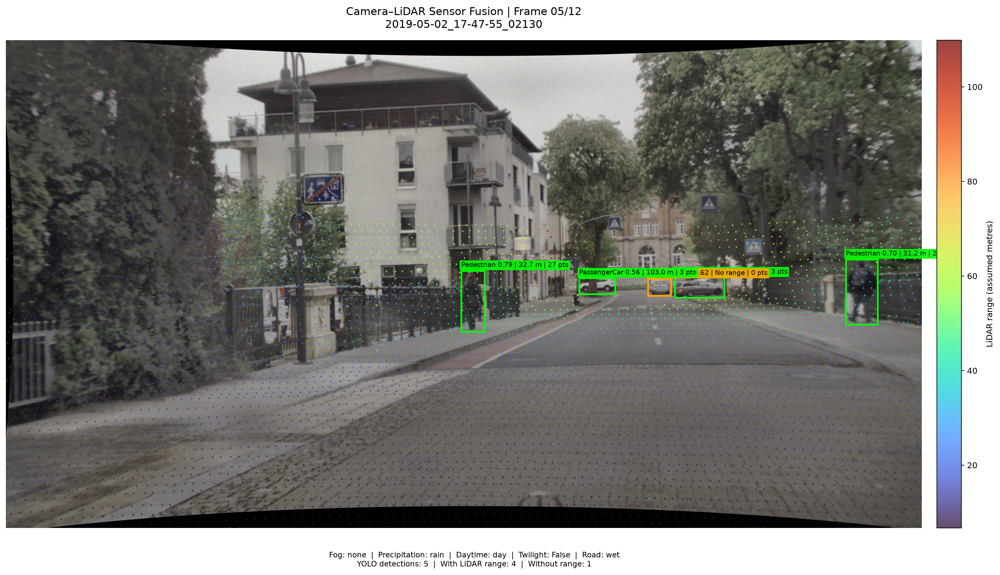

In [15]:
first_figure = (
    ANNOTATED_DIR
    / f"{selected_frame_ids[4]}_annotated.png"
)

display(DisplayImage(filename=str(first_figure)))



In [16]:
# Environmental distribution in the full dataset

print("FOG CONDITION")
display(
    environment_df["fog_condition"]
    .value_counts(dropna=False)
    .to_frame("number_of_images")
)

print("\nPRECIPITATION CONDITION")
display(
    environment_df["precipitation_condition"]
    .value_counts(dropna=False)
    .to_frame("number_of_images")
)

print("\nDAYTIME CONDITION")
display(
    environment_df["daytime_condition"]
    .value_counts(dropna=False)
    .to_frame("number_of_images")
)

print("\nROAD CONDITION")
display(
    environment_df["road_condition"]
    .value_counts(dropna=False)
    .to_frame("number_of_images")
)

FOG CONDITION


,number_of_images
fog_condition,
none,9743
light,1968
dense,1286



PRECIPITATION CONDITION


,number_of_images
precipitation_condition,
none,7978
light_snow,3607
heavy_snow,1130
rain,282



DAYTIME CONDITION


,number_of_images
daytime_condition,
day,7748
night,5249



ROAD CONDITION


,number_of_images
road_condition,
wet,4083
dry,3390
full_snow,3335
partial_snow,2179
unknown,10


In [17]:
# ============================================
# STAGE 4B — Balanced multi-frame sampling
# ============================================

import pandas as pd
from pathlib import Path

SAMPLE_PER_FOG_GROUP = 40
RANDOM_SEED = 42

# 1. Build a table of synchronized RGB-LiDAR pairs
paired_ids = sorted(
    set(rgb_by_stem.keys()) & set(lidar_by_stem.keys())
)

paired_df = pd.DataFrame({"frame_id": paired_ids})

# 2. Attach environmental metadata
sampling_df = paired_df.merge(
    environment_df.assign(
        frame_id=environment_df["image_name"].apply(
            lambda x: Path(str(x)).stem
        )
    )[
        [
            "frame_id",
            "fog_condition",
            "precipitation_condition",
            "daytime_condition",
            "road_condition",
        ]
    ],
    on="frame_id",
    how="left",
    validate="one_to_one",
)

# 3. Check missing metadata
print("Synchronized RGB-LiDAR pairs:", len(paired_df))
print("Missing fog labels:", sampling_df["fog_condition"].isna().sum())

assert sampling_df["fog_condition"].notna().sum() == len(sampling_df)

# 4. Sample equally from each fog category
selected_df = (
    sampling_df
    .groupby("fog_condition", group_keys=False)
    .sample(
        n=SAMPLE_PER_FOG_GROUP,
        random_state=RANDOM_SEED,
    )
    .sort_values(["fog_condition", "frame_id"])
    .reset_index(drop=True)
)

# 5. Store selected frame IDs
selected_frame_ids_120 = selected_df["frame_id"].tolist()

print("\nSelected frames:", len(selected_frame_ids_120))
print("\nFog distribution:")
display(selected_df["fog_condition"].value_counts().to_frame("frames"))

print("\nPrecipitation distribution:")
display(selected_df["precipitation_condition"].value_counts().to_frame("frames"))

print("\nDaytime distribution:")
display(selected_df["daytime_condition"].value_counts().to_frame("frames"))

print("\nRoad condition distribution:")
display(selected_df["road_condition"].value_counts().to_frame("frames"))

# 6. Save sampling manifest
sampling_manifest_path = (
    OUTPUT_DIR / "stage4_120_frame_sampling_manifest.csv"
)

selected_df.to_csv(sampling_manifest_path, index=False)

print("\nSampling manifest saved to:")
print(sampling_manifest_path)

Synchronized RGB-LiDAR pairs: 12997
Missing fog labels: 0

Selected frames: 120

Fog distribution:


,frames
fog_condition,
dense,40
light,40
none,40



Precipitation distribution:


,frames
precipitation_condition,
none,61
light_snow,31
heavy_snow,25
rain,3



Daytime distribution:


,frames
daytime_condition,
day,81
night,39



Road condition distribution:


,frames
road_condition,
full_snow,46
dry,32
wet,27
partial_snow,14
unknown,1



Sampling manifest saved to:
/home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/stage4_120_frame_sampling_manifest.csv


In [18]:
# ============================================
# STAGE 4B — 120-frame camera-LiDAR evaluation
# ============================================

from pathlib import Path
import numpy as np
import pandas as pd

MIN_LIDAR_POINTS_PER_BOX = 3

fusion_rows = []
frame_rows = []

for i, row in selected_df.iterrows():

    frame_id = row["frame_id"]

    # ----------------------------------------
    # 1. Load synchronized RGB and LiDAR
    # ----------------------------------------
    rgb = np.asarray(
        Image.open(rgb_by_stem[frame_id]).convert("RGB")
    )

    raw_lidar = np.fromfile(
        lidar_by_stem[frame_id],
        dtype=np.float32
    )

    if raw_lidar.size % 5 != 0:
        print(f"Skipping invalid LiDAR file: {frame_id}")
        continue

    xyz = raw_lidar.reshape(-1, 5)[:, :3]

    # ----------------------------------------
    # 2. YOLO inference
    # ----------------------------------------
    result = generalist_model.predict(
        source=rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    detections = []

    if result.boxes is not None:
        for box in result.boxes:

            xyxy = (
                box.xyxy[0]
                .detach()
                .cpu()
                .numpy()
                .astype(float)
            )

            class_id = int(box.cls.item())
            confidence = float(box.conf.item())

            class_name = (
                generalist_model.names[class_id]
            )

            detections.append({
                "class_id": class_id,
                "class_name": str(class_name),
                "confidence": confidence,
                "xyxy": xyxy,
            })

    # ----------------------------------------
    # 3. Project LiDAR onto the RGB image
    # ----------------------------------------
    projection = project_lidar_points(
        xyz=xyz,
        vtc=VTC,
        image_shape=rgb.shape,
    )

    # ----------------------------------------
    # 4. Associate projected points with boxes
    # ----------------------------------------
    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    # ----------------------------------------
    # 5. Store detection-level results
    # ----------------------------------------
    n_with_range = 0

    for item in associations:

        has_range = item["status"] == "estimated"

        if has_range:
            n_with_range += 1

        fusion_rows.append({
            "frame_id": frame_id,
            "fog_condition": row["fog_condition"],
            "precipitation_condition": row["precipitation_condition"],
            "daytime_condition": row["daytime_condition"],
            "road_condition": row["road_condition"],
            "class": item["class_name"],
            "yolo_confidence": item["confidence"],
            "lidar_points_in_box": item["n_lidar_points"],
            "median_lidar_range": item["median_lidar_range"],
            "range_q25": item["range_q25"],
            "range_q75": item["range_q75"],
            "range_status": item["status"],
        })

    # ----------------------------------------
    # 6. Store frame-level results
    # ----------------------------------------
    frame_rows.append({
        "frame_id": frame_id,
        "fog_condition": row["fog_condition"],
        "precipitation_condition": row["precipitation_condition"],
        "daytime_condition": row["daytime_condition"],
        "road_condition": row["road_condition"],
        "n_lidar_input": len(xyz),
        "n_lidar_projected": projection["n_projected"],
        "n_yolo_detections": len(detections),
        "n_detections_with_range": n_with_range,
        "n_detections_without_range": len(associations) - n_with_range,
    })

    print(
        f"[{len(frame_rows):03d}/120] {frame_id} | "
        f"Detections: {len(detections)} | "
        f"With range: {n_with_range}"
    )

# ============================================
# 7. Create result DataFrames
# ============================================

fusion_results = pd.DataFrame(fusion_rows)
frame_results = pd.DataFrame(frame_rows)

print("\nEvaluation completed.")
print("Frames processed:", len(frame_results))
print("Total detections:", len(fusion_results))

display(frame_results.head())
display(fusion_results.head())

[001/120] 2018-02-07_18-26-13_00500 | Detections: 2 | With range: 2
[002/120] 2018-02-07_18-26-13_00600 | Detections: 2 | With range: 2
[003/120] 2018-02-12_09-17-17_00430 | Detections: 0 | With range: 0
[004/120] 2018-02-12_16-02-49_00040 | Detections: 1 | With range: 1
[005/120] 2018-02-12_16-58-59_00130 | Detections: 6 | With range: 5
[006/120] 2018-02-12_16-58-59_00280 | Detections: 4 | With range: 4
[007/120] 2018-10-08_08-10-40_02530 | Detections: 2 | With range: 2
[008/120] 2018-10-08_08-10-40_02640 | Detections: 1 | With range: 0
[009/120] 2018-10-08_08-10-40_02730 | Detections: 1 | With range: 1
[010/120] 2018-10-08_08-10-40_03020 | Detections: 4 | With range: 3
[011/120] 2018-10-08_08-18-59_00370 | Detections: 2 | With range: 2
[012/120] 2018-10-08_08-18-59_03700 | Detections: 3 | With range: 3
[013/120] 2018-10-08_08-18-59_04800 | Detections: 4 | With range: 4
[014/120] 2018-10-08_08-27-03_01050 | Detections: 3 | With range: 2
[015/120] 2018-10-08_08-27-03_01770 | Detections

,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,n_lidar_input,n_lidar_projected,n_yolo_detections,n_detections_with_range,n_detections_without_range
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,55146,4536,2,2,0
1,2018-02-07_18-26-13_00600,dense,none,night,full_snow,55125,4500,2,2,0
2,2018-02-12_09-17-17_00430,dense,heavy_snow,day,partial_snow,55304,3694,0,0,0
3,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,55229,4436,1,1,0
4,2018-02-12_16-58-59_00130,dense,heavy_snow,night,full_snow,55036,4446,6,5,1


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.835323,44,23.854698,23.418319,31.593090,estimated
1,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.771204,43,23.406321,23.292872,25.468864,estimated
2,2018-02-07_18-26-13_00600,dense,none,night,full_snow,Pedestrian,0.853929,264,9.874117,9.733761,13.954299,estimated
3,2018-02-07_18-26-13_00600,dense,none,night,full_snow,PassengerCar,0.532352,29,73.878593,67.007301,76.429260,estimated
4,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,RidableVehicle,0.752459,27,30.174017,29.772502,30.280407,estimated


In [19]:
# Save detection-level and frame-level results

fusion_csv = OUTPUT_DIR / "stage4_120_frame_fusion_results.csv"
frame_csv = OUTPUT_DIR / "stage4_120_frame_summary.csv"

fusion_results.to_csv(fusion_csv, index=False)
frame_results.to_csv(frame_csv, index=False)

print("Detection results:", fusion_csv)
print("Frame summary:", frame_csv)

Detection results: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/stage4_120_frame_fusion_results.csv
Frame summary: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/stage4_120_frame_summary.csv


In [20]:
# ============================================
# FUSION PERFORMANCE BY FOG CONDITION
# ============================================

fog_summary = (
    frame_results
    .groupby("fog_condition")
    .agg(
        frames=("frame_id", "nunique"),
        total_detections=("n_yolo_detections", "sum"),
        detections_with_range=("n_detections_with_range", "sum"),
        detections_without_range=("n_detections_without_range", "sum"),
        mean_projected_lidar_points=("n_lidar_projected", "mean"),
    )
    .reset_index()
)

fog_summary["range_availability_pct"] = (
    100
    * fog_summary["detections_with_range"]
    / fog_summary["total_detections"].replace(0, np.nan)
)

display(fog_summary.round(2))

,fog_condition,frames,total_detections,detections_with_range,detections_without_range,mean_projected_lidar_points,range_availability_pct
0,dense,40,101,88,13,3252.82,87.13
1,light,40,168,155,13,4332.92,92.26
2,none,40,301,273,28,4666.82,90.70


In [21]:
class_fog_summary = (
    fusion_results
    .groupby(["fog_condition", "class"])
    .agg(
        detections=("frame_id", "size"),
        with_range=(
            "range_status",
            lambda x: (x == "estimated").sum()
        ),
        median_lidar_points=("lidar_points_in_box", "median"),
        median_range=("median_lidar_range", "median"),
    )
    .reset_index()
)

class_fog_summary["range_availability_pct"] = (
    100 * class_fog_summary["with_range"]
    / class_fog_summary["detections"]
)

display(class_fog_summary.round(2))

,fog_condition,class,detections,with_range,median_lidar_points,median_range,range_availability_pct
0,dense,LargeVehicle,12,10,132.0,30.62,83.33
1,dense,PassengerCar,64,55,19.0,36.62,85.94
2,dense,Pedestrian,24,22,24.5,23.97,91.67
3,dense,RidableVehicle,1,1,27.0,30.17,100.00
4,light,LargeVehicle,9,8,48.0,43.43,88.89
5,light,PassengerCar,108,101,28.0,44.63,93.52
6,light,Pedestrian,51,46,11.0,37.62,90.20
7,none,LargeVehicle,10,9,128.0,43.97,90.00
8,none,PassengerCar,173,160,27.0,43.69,92.49
9,none,Pedestrian,117,103,16.0,36.62,88.03


In [22]:
# ============================================
# STAGE 4C — Select representative detections
# ============================================

# Keep detections with enough LiDAR points
candidates = fusion_results[
    fusion_results["range_status"] == "estimated"
].copy()

# Select up to two examples per fog/class combination.
# Prefer detections with more LiDAR points.
representative_cases = (
    candidates
    .sort_values(
        ["lidar_points_in_box", "yolo_confidence"],
        ascending=[False, False]
    )
    .groupby(["fog_condition", "class"], group_keys=False)
    .head(2)
    .reset_index(drop=True)
)

# Limit the first analysis to 12 examples
representative_cases = representative_cases.head(12)

print("Selected cases:", len(representative_cases))

display(
    representative_cases[
        [
            "frame_id",
            "fog_condition",
            "class",
            "yolo_confidence",
            "lidar_points_in_box",
            "median_lidar_range",
            "range_q25",
            "range_q75",
        ]
    ].round(2)
)

Selected cases: 12


,frame_id,fog_condition,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75
0,2018-02-03_20-52-49_00000,none,PassengerCar,0.62,4108,8.42,7.05,10.43
1,2018-02-03_20-52-49_00000,none,PassengerCar,0.41,4075,8.08,6.60,10.25
2,2018-02-12_16-58-59_00280,dense,PassengerCar,0.93,1043,13.01,12.83,14.49
3,2018-02-12_15-52-57_00200,light,PassengerCar,0.89,898,11.65,11.43,23.56
4,2018-10-08_08-18-59_00370,dense,LargeVehicle,0.97,755,12.47,12.40,12.57
5,2018-02-12_14-51-16_00100,light,PassengerCar,0.94,684,12.48,11.15,44.35
6,2018-12-17_06-30-54_14700,light,LargeVehicle,0.90,577,15.23,15.10,15.45
7,2018-10-08_08-50-46_07300,dense,PassengerCar,0.94,541,9.46,9.16,28.98
8,2018-12-21_16-34-49_01000,none,LargeVehicle,0.93,383,26.82,26.57,31.50
9,2018-02-07_18-26-13_00600,dense,Pedestrian,0.85,264,9.87,9.73,13.95


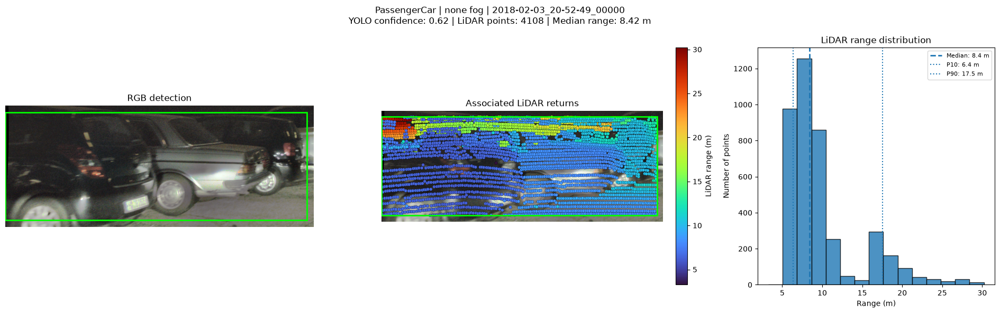

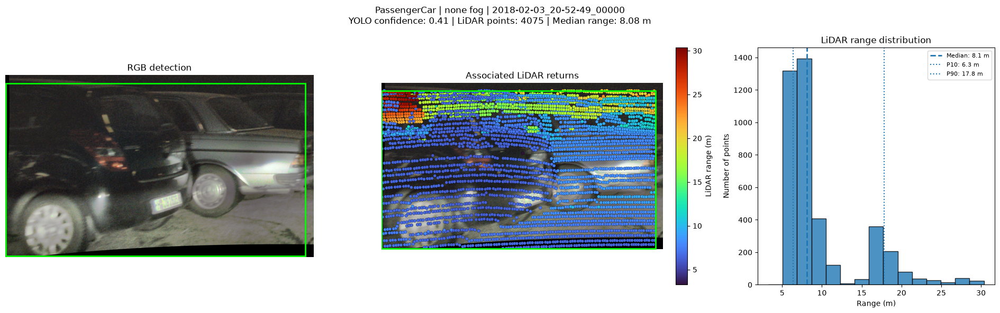

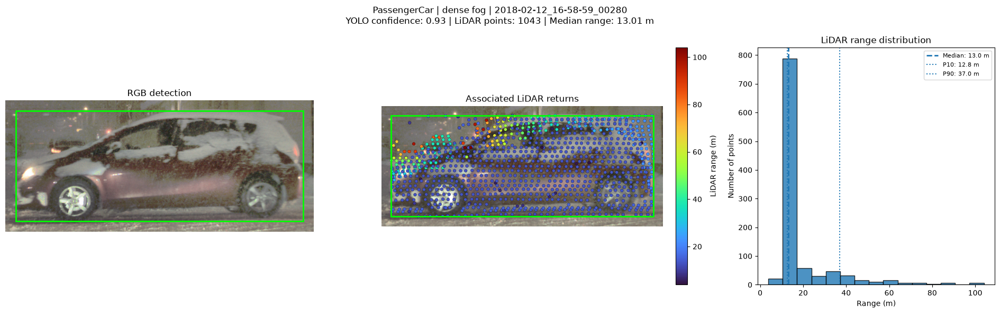

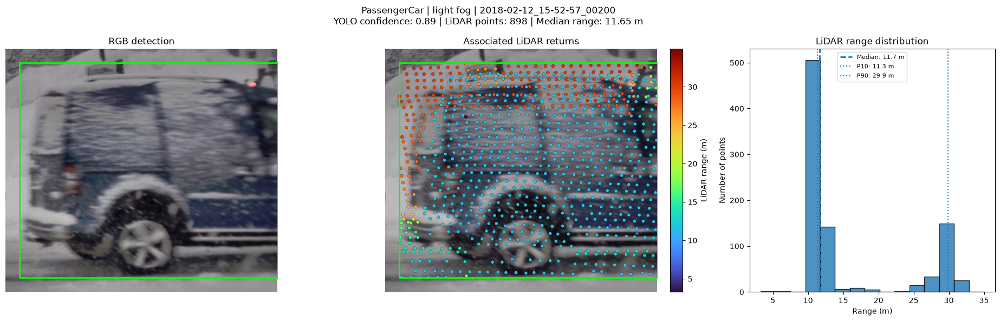

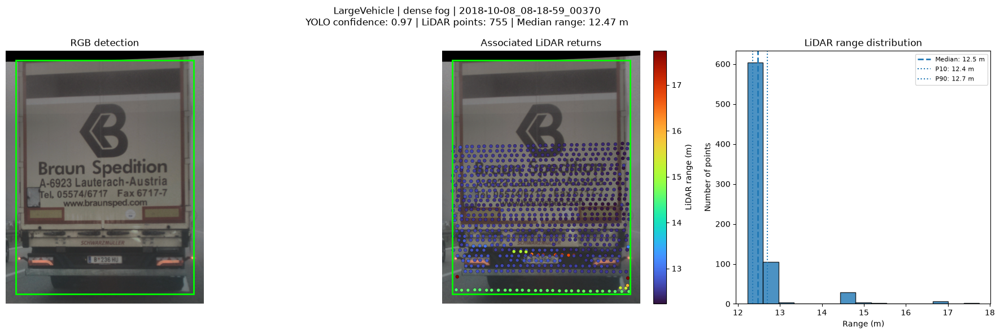

...

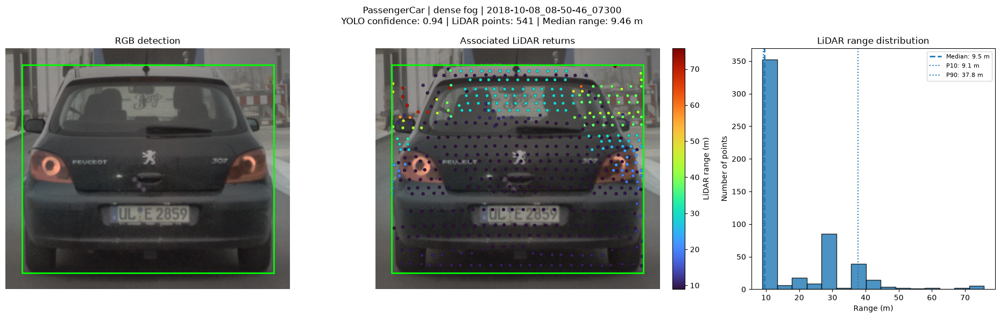

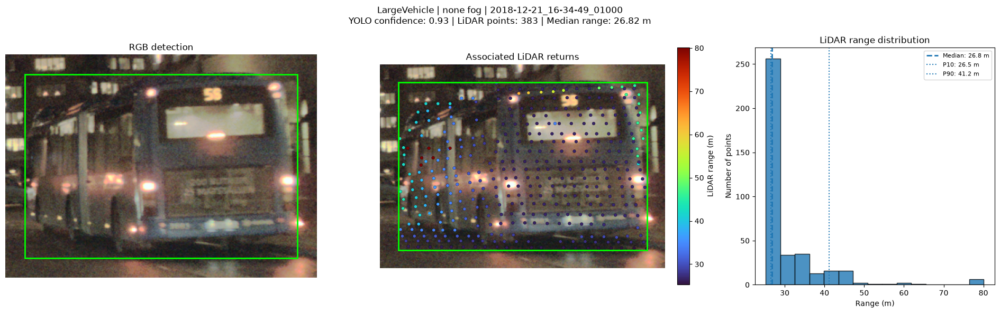

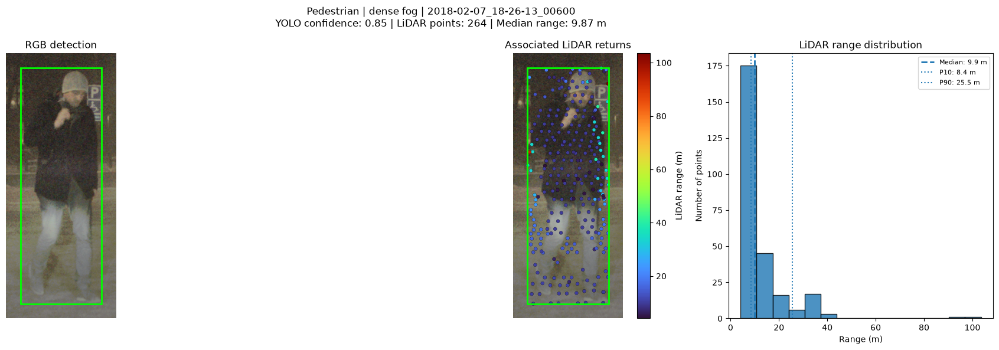

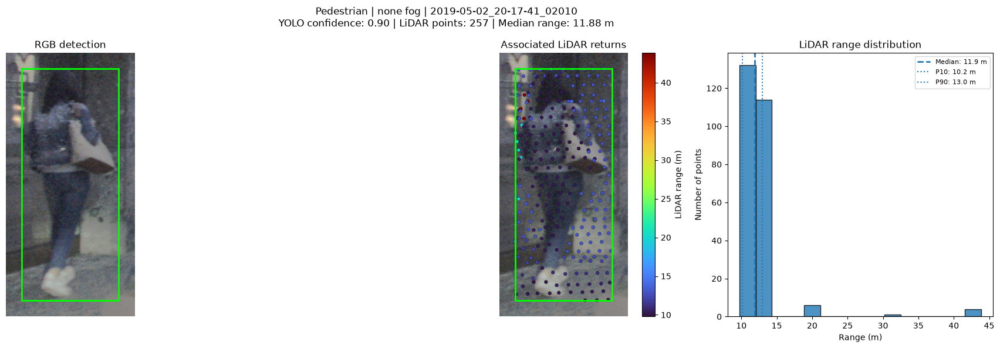

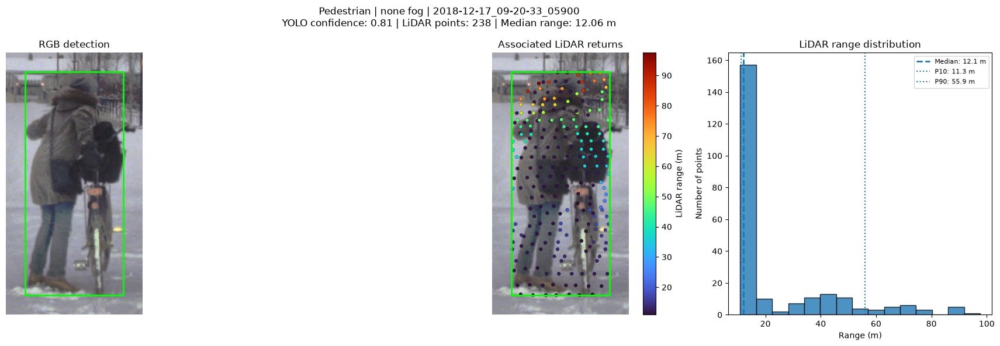

,frame_id,class,fog_condition,yolo_confidence,n_lidar_points,range_min,range_p10,range_q25,range_median,range_q75,range_p90,range_max,range_iqr,range_p90_p10_spread,figure_path
0,2018-02-03_20-52-49_00000,PassengerCar,none,0.62,4108,3.26,6.36,7.05,8.42,10.43,17.52,30.219999,3.37,11.16,/home/maritza/projects/autonomous_vehicle/outp...
1,2018-02-03_20-52-49_00000,PassengerCar,none,0.41,4075,3.26,6.35,6.60,8.08,10.25,17.84,30.360001,3.66,11.49,/home/maritza/projects/autonomous_vehicle/outp...
2,2018-02-12_16-58-59_00280,PassengerCar,dense,0.93,1043,3.82,12.76,12.83,13.01,14.49,36.96,104.059998,1.66,24.20,/home/maritza/projects/autonomous_vehicle/outp...
3,2018-02-12_15-52-57_00200,PassengerCar,light,0.89,898,3.26,11.32,11.43,11.65,23.56,29.88,34.970001,12.13,18.57,/home/maritza/projects/autonomous_vehicle/outp...
4,2018-10-08_08-18-59_00370,LargeVehicle,dense,0.97,755,12.23,12.36,12.40,12.47,12.57,12.71,17.740000,0.17,0.35,/home/maritza/projects/autonomous_vehicle/outp...
5,2018-02-12_14-51-16_00100,PassengerCar,light,0.94,684,8.35,10.56,11.15,12.48,44.35,95.83,104.010002,33.19,85.27,/home/maritza/projects/autonomous_vehicle/outp...
6,2018-12-17_06-30-54_14700,LargeVehicle,light,0.90,577,2.96,15.03,15.10,15.23,15.45,17.95,58.209999,0.35,2.92,/home/maritza/projects/autonomous_vehicle/outp...
7,2018-10-08_08-50-46_07300,PassengerCar,dense,0.94,541,8.91,9.11,9.16,9.46,28.98,37.76,75.730003,19.83,28.66,/home/maritza/projects/autonomous_vehicle/outp...
8,2018-12-21_16-34-49_01000,LargeVehicle,none,0.93,383,25.24,26.47,26.57,26.82,31.50,41.16,80.110001,4.93,14.68,/home/maritza/projects/autonomous_vehicle/outp...
9,2018-02-07_18-26-13_00600,Pedestrian,dense,0.85,264,4.11,8.40,9.73,9.87,13.95,25.53,103.580002,4.22,17.14,/home/maritza/projects/autonomous_vehicle/outp...


In [23]:
# ============================================
# STAGE 4C — Visualize object-level association
# ============================================

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

ASSOCIATION_DIR = OUTPUT_DIR / "association_quality"
ASSOCIATION_DIR.mkdir(parents=True, exist_ok=True)

association_diagnostics = []

for case_number, case in representative_cases.iterrows():

    frame_id = case["frame_id"]

    # ----------------------------------------
    # 1. Load RGB and LiDAR
    # ----------------------------------------
    rgb = np.asarray(
        Image.open(rgb_by_stem[frame_id]).convert("RGB")
    )

    raw_lidar = np.fromfile(
        lidar_by_stem[frame_id],
        dtype=np.float32
    )

    xyz = raw_lidar.reshape(-1, 5)[:, :3]

    # ----------------------------------------
    # 2. Re-run YOLO
    # ----------------------------------------
    result = generalist_model.predict(
        source=rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    detections = []

    if result.boxes is not None:
        for box in result.boxes:

            class_id = int(box.cls.item())

            class_name = (
                generalist_model.names[class_id]
            )

            detections.append({
                "class_id": class_id,
                "class_name": str(class_name),
                "confidence": float(box.conf.item()),
                "xyxy": (
                    box.xyxy[0]
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(float)
                ),
            })

    # ----------------------------------------
    # 3. Project LiDAR
    # ----------------------------------------
    projection = project_lidar_points(
        xyz=xyz,
        vtc=VTC,
        image_shape=rgb.shape,
    )

    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    # ----------------------------------------
    # 4. Match the selected detection
    # ----------------------------------------
    matching = [
        item for item in associations
        if (
            item["class_name"] == case["class"]
            and item["status"] == "estimated"
            and item["n_lidar_points"] == case["lidar_points_in_box"]
            and np.isclose(
                item["median_lidar_range"],
                case["median_lidar_range"],
                atol=0.01,
            )
        )
    ]

    if not matching:
        print(f"Could not match selected detection: {frame_id}")
        continue

    item = matching[0]

    x1, y1, x2, y2 = item["bbox_xyxy"]

    # Points associated with this detection
    point_indices = item["associated_original_indices"]

    # Recover their XYZ coordinates from the original LiDAR
    associated_xyz = xyz[point_indices]

    point_ranges = np.linalg.norm(
        associated_xyz,
        axis=1,
    )

    median_range = np.median(point_ranges)
    q10, q25, q75, q90 = np.percentile(
        point_ranges,
        [10, 25, 75, 90],
    )

    # ----------------------------------------
    # 5. Plot RGB crop and LiDAR points
    # ----------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 6),
        gridspec_kw={"width_ratios": [1.3, 1.3, 1]},
    )

    # Original RGB image with detection
    axes[0].imshow(rgb)
    axes[0].add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2,
        )
    )
    axes[0].set_xlim(max(0, x1 - 30), min(rgb.shape[1], x2 + 30))
    axes[0].set_ylim(min(rgb.shape[0], y2 + 30), max(0, y1 - 30))
    axes[0].set_title("RGB detection")
    axes[0].axis("off")

    # Projected LiDAR points inside the bounding box
    axes[1].imshow(rgb)
    scatter = axes[1].scatter(
        projection["u"][
            (projection["original_indices"][:, None] == point_indices).any(axis=1)
        ],
        projection["v"][
            (projection["original_indices"][:, None] == point_indices).any(axis=1)
        ],
        c=point_ranges,
        cmap="turbo",
        s=18,
        edgecolors="black",
        linewidths=0.2,
    )

    axes[1].add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2,
        )
    )

    axes[1].set_xlim(max(0, x1 - 30), min(rgb.shape[1], x2 + 30))
    axes[1].set_ylim(min(rgb.shape[0], y2 + 30), max(0, y1 - 30))
    axes[1].set_title("Associated LiDAR returns")
    axes[1].axis("off")

    fig.colorbar(
        scatter,
        ax=axes[1],
        fraction=0.046,
        pad=0.04,
        label="LiDAR range (m)",
    )

    # Range distribution
    axes[2].hist(
        point_ranges,
        bins=min(15, max(5, len(point_ranges) // 3)),
        edgecolor="black",
        alpha=0.8,
    )

    axes[2].axvline(
        median_range,
        linestyle="--",
        linewidth=2,
        label=f"Median: {median_range:.1f} m",
    )

    axes[2].axvline(
        q10,
        linestyle=":",
        label=f"P10: {q10:.1f} m",
    )

    axes[2].axvline(
        q90,
        linestyle=":",
        label=f"P90: {q90:.1f} m",
    )

    axes[2].set_title("LiDAR range distribution")
    axes[2].set_xlabel("Range (m)")
    axes[2].set_ylabel("Number of points")
    axes[2].legend(fontsize=8)

    fig.suptitle(
        f"{case['class']} | {case['fog_condition']} fog | "
        f"{frame_id}\n"
        f"YOLO confidence: {item['confidence']:.2f} | "
        f"LiDAR points: {len(point_ranges)} | "
        f"Median range: {median_range:.2f} m",
        fontsize=12,
    )

    plt.tight_layout()

    output_path = (
        ASSOCIATION_DIR
        / f"case_{case_number + 1:02d}_{frame_id}.png"
    )

    fig.savefig(
        output_path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    # ----------------------------------------
    # 6. Store diagnostic statistics
    # ----------------------------------------
    association_diagnostics.append({
        "frame_id": frame_id,
        "class": item["class_name"],
        "fog_condition": case["fog_condition"],
        "yolo_confidence": item["confidence"],
        "n_lidar_points": len(point_ranges),
        "range_min": point_ranges.min(),
        "range_p10": q10,
        "range_q25": q25,
        "range_median": median_range,
        "range_q75": q75,
        "range_p90": q90,
        "range_max": point_ranges.max(),
        "range_iqr": q75 - q25,
        "range_p90_p10_spread": q90 - q10,
        "figure_path": str(output_path),
    })

association_diagnostics_df = pd.DataFrame(
    association_diagnostics
)

display(association_diagnostics_df.round(2))

In [24]:
# ============================================
# STAGE 4C — Bounding box and range diagnostics
# ============================================

diagnostic_rows = []

for _, case in representative_cases.iterrows():

    frame_id = case["frame_id"]

    # Load RGB dimensions
    rgb = np.asarray(
        Image.open(rgb_by_stem[frame_id]).convert("RGB")
    )

    image_height, image_width = rgb.shape[:2]
    image_area = image_width * image_height

    # Re-run YOLO
    result = generalist_model.predict(
        source=rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    detections = []

    if result.boxes is not None:
        for box in result.boxes:

            class_id = int(box.cls.item())

            class_name = generalist_model.names[class_id]

            detections.append({
                "class_id": class_id,
                "class_name": str(class_name),
                "confidence": float(box.conf.item()),
                "xyxy": (
                    box.xyxy[0]
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(float)
                ),
            })

    # Load and project LiDAR
    raw_lidar = np.fromfile(
        lidar_by_stem[frame_id],
        dtype=np.float32
    )

    xyz = raw_lidar.reshape(-1, 5)[:, :3]

    projection = project_lidar_points(
        xyz=xyz,
        vtc=VTC,
        image_shape=rgb.shape,
    )

    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    # Match the selected case
    matches = [
        item for item in associations
        if (
            item["class_name"] == case["class"]
            and item["status"] == "estimated"
            and item["n_lidar_points"] == case["lidar_points_in_box"]
            and np.isclose(
                item["median_lidar_range"],
                case["median_lidar_range"],
                atol=0.01,
            )
        )
    ]

    if not matches:
        continue

    item = matches[0]

    x1, y1, x2, y2 = item["bbox_xyxy"]

    box_width = max(0, x2 - x1)
    box_height = max(0, y2 - y1)
    box_area = box_width * box_height

    area_ratio = box_area / image_area

    diagnostic_rows.append({
        "frame_id": frame_id,
        "class": item["class_name"],
        "fog_condition": case["fog_condition"],
        "confidence": item["confidence"],
        "bbox_width": box_width,
        "bbox_height": box_height,
        "bbox_area_ratio_pct": area_ratio * 100,
        "lidar_points": item["n_lidar_points"],
        "points_per_10000_pixels": (
            item["n_lidar_points"] / box_area * 10000
            if box_area > 0 else np.nan
        ),
        "median_range_m": item["median_lidar_range"],
        "range_iqr_m": (
            item["range_q75"] - item["range_q25"]
        ),
        "range_p90_p10_spread_m": (
            item["range_q75"] - item["range_q25"]
        ),
    })

diagnostic_df = pd.DataFrame(diagnostic_rows)

display(
    diagnostic_df.round(2)
)

,frame_id,class,fog_condition,confidence,bbox_width,bbox_height,bbox_area_ratio_pct,lidar_points,points_per_10000_pixels,median_range_m,range_iqr_m,range_p90_p10_spread_m
0,2018-02-03_20-52-49_00000,PassengerCar,none,0.62,1316.52,472.13,31.61,4108,66.09,8.42,3.37,3.37
1,2018-02-03_20-52-49_00000,PassengerCar,none,0.41,1060.98,613.46,33.10,4075,62.61,8.08,3.66,3.66
2,2018-02-12_16-58-59_00280,PassengerCar,dense,0.93,818.77,315.60,13.14,1043,40.36,13.01,1.66,1.66
3,2018-02-12_15-52-57_00200,PassengerCar,light,0.89,541.47,450.97,12.42,898,36.78,11.65,12.13,12.13
4,2018-10-08_08-18-59_00370,LargeVehicle,dense,0.97,527.63,694.78,18.65,755,20.60,12.47,0.17,0.17
5,2018-02-12_14-51-16_00100,PassengerCar,light,0.94,455.71,436.42,10.12,684,34.39,12.48,33.19,33.19
6,2018-12-17_06-30-54_14700,LargeVehicle,light,0.90,527.08,685.86,18.39,577,15.96,15.23,0.35,0.35
7,2018-10-08_08-50-46_07300,PassengerCar,dense,0.94,460.29,382.02,8.94,541,30.77,9.46,19.83,19.83
8,2018-12-21_16-34-49_01000,LargeVehicle,none,0.93,412.10,278.76,5.84,383,33.34,26.82,4.93,4.93
9,2018-02-07_18-26-13_00600,Pedestrian,dense,0.85,166.88,486.17,4.13,264,32.54,9.87,4.22,4.22


In [25]:
# Correct the range spread metrics

corrected_diagnostics = diagnostic_df.copy()

assert len(corrected_diagnostics) == len(association_diagnostics_df)

corrected_diagnostics["range_p10_m"] = (
    association_diagnostics_df["range_p10"].values
)

corrected_diagnostics["range_p90_m"] = (
    association_diagnostics_df["range_p90"].values
)

corrected_diagnostics["range_iqr_m"] = (
    association_diagnostics_df["range_iqr"].values
)

corrected_diagnostics["range_p90_p10_spread_m"] = (
    corrected_diagnostics["range_p90_m"]
    - corrected_diagnostics["range_p10_m"]
)

display(
    corrected_diagnostics[
        [
            "frame_id",
            "class",
            "fog_condition",
            "bbox_area_ratio_pct",
            "lidar_points",
            "median_range_m",
            "range_iqr_m",
            "range_p90_p10_spread_m",
        ]
    ].round(2)
)

,frame_id,class,fog_condition,bbox_area_ratio_pct,lidar_points,median_range_m,range_iqr_m,range_p90_p10_spread_m
0,2018-02-03_20-52-49_00000,PassengerCar,none,31.61,4108,8.42,3.37,11.16
1,2018-02-03_20-52-49_00000,PassengerCar,none,33.10,4075,8.08,3.66,11.49
2,2018-02-12_16-58-59_00280,PassengerCar,dense,13.14,1043,13.01,1.66,24.20
3,2018-02-12_15-52-57_00200,PassengerCar,light,12.42,898,11.65,12.13,18.57
4,2018-10-08_08-18-59_00370,LargeVehicle,dense,18.65,755,12.47,0.17,0.35
5,2018-02-12_14-51-16_00100,PassengerCar,light,10.12,684,12.48,33.19,85.27
6,2018-12-17_06-30-54_14700,LargeVehicle,light,18.39,577,15.23,0.35,2.92
7,2018-10-08_08-50-46_07300,PassengerCar,dense,8.94,541,9.46,19.83,28.66
8,2018-12-21_16-34-49_01000,LargeVehicle,none,5.84,383,26.82,4.93,14.68
9,2018-02-07_18-26-13_00600,Pedestrian,dense,4.13,264,9.87,4.22,17.14


In [31]:
# ============================================
# STAGE 4D — 3D DBSCAN association experiment
# ============================================

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

DBSCAN_EPS = 0.8       # metres (assumed XYZ units)
DBSCAN_MIN_SAMPLES = 10

dbscan_rows = []

for _, case in representative_cases.iterrows():

    frame_id = case["frame_id"]

    # Load synchronized data
    rgb = np.asarray(
        Image.open(rgb_by_stem[frame_id]).convert("RGB")
    )

    raw_lidar = np.fromfile(
        lidar_by_stem[frame_id],
        dtype=np.float32
    )

    xyz = raw_lidar.reshape(-1, 5)[:, :3]

    # YOLO inference
    result = generalist_model.predict(
        source=rgb,
        imgsz=IMAGE_SIZE,
        conf=CONFIDENCE_THRESHOLD,
        device=DEVICE,
        verbose=False,
    )[0]

    detections = []

    if result.boxes is not None:
        for box in result.boxes:

            class_id = int(box.cls.item())

            detections.append({
                "class_id": class_id,
                "class_name": str(
                    generalist_model.names[class_id]
                ),
                "confidence": float(box.conf.item()),
                "xyxy": (
                    box.xyxy[0]
                    .detach()
                    .cpu()
                    .numpy()
                    .astype(float)
                ),
            })

    # LiDAR projection and association
    projection = project_lidar_points(
        xyz=xyz,
        vtc=VTC,
        image_shape=rgb.shape,
    )

    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=MIN_LIDAR_POINTS_PER_BOX,
    )

    # Match the representative detection
    matches = [
        item for item in associations
        if (
            item["class_name"] == case["class"]
            and item["status"] == "estimated"
            and item["n_lidar_points"] == case["lidar_points_in_box"]
            and np.isclose(
                item["median_lidar_range"],
                case["median_lidar_range"],
                atol=0.01,
            )
        )
    ]

    if not matches:
        print("Could not match:", frame_id, case["class"])
        continue

    item = matches[0]

    # Recover original 3D LiDAR points
    point_indices = np.asarray(
        item["associated_original_indices"],
        dtype=int,
    )

    associated_xyz = xyz[point_indices]

    if len(associated_xyz) < DBSCAN_MIN_SAMPLES:
        continue

    # Baseline range
    all_ranges = np.linalg.norm(
        associated_xyz,
        axis=1,
    )

    baseline_median = float(np.median(all_ranges))
    baseline_iqr = float(
        np.percentile(all_ranges, 75)
        - np.percentile(all_ranges, 25)
    )

    # ----------------------------------------
    # DBSCAN in 3D XYZ
    # ----------------------------------------
    cluster_labels = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES,
    ).fit_predict(associated_xyz)

    valid_labels = [
        label for label in np.unique(cluster_labels)
        if label != -1
    ]

    noise_count = int(np.sum(cluster_labels == -1))

    if not valid_labels:
        dbscan_rows.append({
            "frame_id": frame_id,
            "class": case["class"],
            "fog_condition": case["fog_condition"],
            "n_points": len(associated_xyz),
            "n_clusters": 0,
            "noise_points": noise_count,
            "noise_pct": 100 * noise_count / len(associated_xyz),
            "baseline_median_m": baseline_median,
            "baseline_iqr_m": baseline_iqr,
            "largest_cluster_points": 0,
            "cluster_median_m": np.nan,
            "cluster_iqr_m": np.nan,
            "cluster_p90_p10_m": np.nan,
        })
        continue

    # Identify largest non-noise cluster
    cluster_sizes = {
        label: int(np.sum(cluster_labels == label))
        for label in valid_labels
    }

    largest_label = max(
        cluster_sizes,
        key=cluster_sizes.get,
    )

    largest_mask = cluster_labels == largest_label

    largest_xyz = associated_xyz[largest_mask]

    cluster_ranges = np.linalg.norm(
        largest_xyz,
        axis=1,
    )

    cluster_median = float(np.median(cluster_ranges))
    cluster_iqr = float(
        np.percentile(cluster_ranges, 75)
        - np.percentile(cluster_ranges, 25)
    )

    cluster_p90_p10 = float(
        np.percentile(cluster_ranges, 90)
        - np.percentile(cluster_ranges, 10)
    )

    dbscan_rows.append({
        "frame_id": frame_id,
        "class": case["class"],
        "fog_condition": case["fog_condition"],
        "n_points": len(associated_xyz),
        "n_clusters": len(valid_labels),
        "noise_points": noise_count,
        "noise_pct": 100 * noise_count / len(associated_xyz),
        "baseline_median_m": baseline_median,
        "baseline_iqr_m": baseline_iqr,
        "largest_cluster_points": len(largest_xyz),
        "largest_cluster_pct": (
            100 * len(largest_xyz) / len(associated_xyz)
        ),
        "cluster_median_m": cluster_median,
        "cluster_iqr_m": cluster_iqr,
        "cluster_p90_p10_m": cluster_p90_p10,
        "median_difference_m": (
            cluster_median - baseline_median
        ),
    })

dbscan_results = pd.DataFrame(dbscan_rows)

display(dbscan_results.round(2))

,frame_id,class,fog_condition,n_points,n_clusters,noise_points,noise_pct,baseline_median_m,baseline_iqr_m,largest_cluster_points,largest_cluster_pct,cluster_median_m,cluster_iqr_m,cluster_p90_p10_m,median_difference_m
0,2018-02-03_20-52-49_00000,PassengerCar,none,4108,7,53,1.29,8.42,3.37,3362,81.84,8.17,2.70,4.02,-0.25
1,2018-02-03_20-52-49_00000,PassengerCar,none,4075,7,37,0.91,8.08,3.66,3226,79.17,7.24,1.81,2.91,-0.84
2,2018-02-12_16-58-59_00280,PassengerCar,dense,1043,5,167,16.01,13.01,1.66,776,74.40,12.93,0.29,0.60,-0.09
3,2018-02-12_15-52-57_00200,PassengerCar,light,898,5,42,4.68,11.65,12.13,615,68.49,11.51,0.29,0.52,-0.14
4,2018-10-08_08-18-59_00370,LargeVehicle,dense,755,2,13,1.72,12.47,0.17,711,94.17,12.46,0.15,0.28,-0.01
5,2018-02-12_14-51-16_00100,PassengerCar,light,684,1,177,25.88,12.48,33.19,507,74.12,11.74,2.09,3.36,-0.74
6,2018-12-17_06-30-54_14700,LargeVehicle,light,577,2,67,11.61,15.23,0.35,501,86.83,15.19,0.26,0.57,-0.04
7,2018-10-08_08-50-46_07300,PassengerCar,dense,541,4,96,17.74,9.46,19.83,331,61.18,9.18,0.25,0.86,-0.29
8,2018-12-21_16-34-49_01000,LargeVehicle,none,383,2,149,38.90,26.82,4.93,218,56.92,26.63,0.25,0.43,-0.19
9,2018-02-07_18-26-13_00600,Pedestrian,dense,264,3,74,28.03,9.87,4.22,157,59.47,9.80,0.19,0.70,-0.07


In [32]:
# Inspect variables potentially related to the DBSCAN experiment

keywords = [
    "cluster",
    "diagnostic",
    "representative",
    "associated",
    "dbscan",
    "xyz",
    "fusion"
]

matching_variables = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in keywords)
]

print("Potentially relevant variables:")
for name in sorted(matching_variables):
    value = globals()[name]
    print(f"{name}: {type(value).__name__}", end="")

    if hasattr(value, "shape"):
        print(f" | shape: {value.shape}")
    elif isinstance(value, (list, tuple, dict)):
        print(f" | length: {len(value)}")
    else:
        print()

Potentially relevant variables:
DBSCAN: type
DBSCAN_EPS: float
DBSCAN_MIN_SAMPLES: int
associated_xyz: ndarray | shape: (238, 3)
association_diagnostics: list | length: 12
association_diagnostics_df: DataFrame | shape: (12, 15)
cluster_iqr: float
cluster_labels: ndarray | shape: (238,)
cluster_median: float
cluster_p90_p10: float
cluster_ranges: ndarray | shape: (137,)
cluster_sizes: dict | length: 1
corrected_diagnostics: DataFrame | shape: (12, 14)
dbscan_results: DataFrame | shape: (12, 15)
dbscan_rows: list | length: 12
diagnostic_df: DataFrame | shape: (12, 12)
diagnostic_rows: list | length: 12
frame_xyz: ndarray | shape: (55406, 3)
fusion_csv: PosixPath
fusion_results: DataFrame | shape: (570, 12)
fusion_rows: list | length: 570
fusion_table: DataFrame | shape: (1, 8)
largest_xyz: ndarray | shape: (137, 3)
representative_cases: DataFrame | shape: (12, 12)
xyz: ndarray | shape: (54575, 3)
xyz_lidar: ndarray | shape: (55602, 3)


In [33]:
print("Current DBSCAN case")
print("-------------------")

print("associated_xyz:", associated_xyz.shape)
print("cluster_labels:", cluster_labels.shape)
print("largest_xyz:", largest_xyz.shape)

print("\nCluster labels and counts:")
print(pd.Series(cluster_labels).value_counts().sort_index())

print("\nLargest cluster:")
print("Points:", len(largest_xyz))

print("\nLast DBSCAN result:")
display(dbscan_results.tail(3))

Current DBSCAN case
-------------------
associated_xyz: (238, 3)
cluster_labels: (238,)
largest_xyz: (137, 3)

Cluster labels and counts:
-1    101
 0    137
Name: count, dtype: int64

Largest cluster:
Points: 137

Last DBSCAN result:


,frame_id,class,fog_condition,n_points,n_clusters,noise_points,noise_pct,baseline_median_m,baseline_iqr_m,largest_cluster_points,largest_cluster_pct,cluster_median_m,cluster_iqr_m,cluster_p90_p10_m,median_difference_m
9,2018-02-07_18-26-13_00600,Pedestrian,dense,264,3,74,28.030303,9.874117,4.220538,157,59.469697,9.799261,0.191549,0.699513,-0.074856
10,2019-05-02_20-17-41_02010,Pedestrian,none,257,1,14,5.447471,11.879489,2.568954,243,94.552529,11.141788,2.541999,2.757010,-0.737701
11,2018-12-17_09-20-33_05900,Pedestrian,none,238,1,101,42.436975,12.061005,24.101616,137,57.563025,11.526909,0.391704,0.958283,-0.534096


In [44]:
# Reconstruct DBSCAN representative case 11

import numpy as np
import pandas as pd
import cv2
import torch
from pathlib import Path
from sklearn.cluster import DBSCAN

# Target frame
TARGET_FRAME = "2018-12-17_09-20-33_05900"

# Paths
RGB_DIR = Path(
    "/home/maritza/projects/autonomous_vehicle/dataset/"
    "seeing_through_fog/extracted/cam_stereo_left_lut/"
    "cam_stereo_left_lut"
)

LIDAR_DIR = Path(
    "/home/maritza/projects/autonomous_vehicle/dataset/"
    "seeing_through_fog/extracted/lidar_hdl64_last/"
    "lidar_hdl64_last"
)

MODEL_PATH = Path(
    "/home/maritza/projects/autonomous_vehicle/"
    "models/yolov8n_rgb/best.pt"
)

rgb_path = RGB_DIR / f"{TARGET_FRAME}.png"
lidar_path = LIDAR_DIR / f"{TARGET_FRAME}.bin"

# Verify files
assert rgb_path.exists(), f"RGB file not found: {rgb_path}"
assert lidar_path.exists(), f"LiDAR file not found: {lidar_path}"

# Load RGB
rgb_image = cv2.cvtColor(
    cv2.imread(str(rgb_path)),
    cv2.COLOR_BGR2RGB
)

# Load LiDAR
lidar_data = np.fromfile(lidar_path, dtype=np.float32)
lidar_data = lidar_data.reshape(-1, 5)
target_xyz = lidar_data[:, :3]

print("RGB shape:", rgb_image.shape)
print("LiDAR points:", len(target_xyz))

# Project LiDAR points into camera
target_projection = project_lidar_points(
    target_xyz,
    VTC,
    rgb_image.shape
)

print("Projected points:", len(target_projection["u"]))

# Load YOLO detections
model = YOLO(str(MODEL_PATH))

prediction = model.predict(
    source=rgb_image,
    conf=0.25,
    iou=0.5,
    verbose=False
)[0]

target_detections = []

for box in prediction.boxes:
    xyxy = box.xyxy[0].cpu().numpy()
    class_id = int(box.cls[0].item())
    confidence = float(box.conf[0].item())

    target_detections.append({
        "xyxy": xyxy,
        "class_name": model.names[class_id],
        "confidence": confidence
    })

# Associate LiDAR points with YOLO detections
target_associations = associate_lidar_with_detections(
    target_detections,
    target_projection,
    min_points=3
)

print("\nDetections:", len(target_detections))
print("Associations:", len(target_associations))

for i, association in enumerate(target_associations):
    print(
        i,
        association.get("class_name"),
        "points:",
        len(association.get("associated_original_indices", []))
    )


# Verify that the reconstructed association matches DBSCAN case 11

dbscan_case = dbscan_results.loc[
    dbscan_results["frame_id"] == TARGET_FRAME
].iloc[0]

pedestrian_association = target_associations[0]

current_indices = np.asarray(
    pedestrian_association["associated_original_indices"]
)

print("Target frame:", TARGET_FRAME)
print("Detection class:", pedestrian_association["class_name"])
print("Current associated points:", len(current_indices))
print("Stored DBSCAN labels:", len(cluster_labels))

print("\nOriginal point index comparison:")

if len(current_indices) == len(cluster_labels):
    print("Point counts match.")

    # Compare reconstructed XYZ with the stored XYZ
    reconstructed_xyz = target_xyz[current_indices]

    print(
        "XYZ arrays match:",
        np.allclose(reconstructed_xyz, associated_xyz)
    )

    print(
        "Maximum absolute coordinate difference:",
        np.max(np.abs(reconstructed_xyz - associated_xyz))
    )
else:
    print("Point counts do not match. Further inspection required.")

print("\nDBSCAN summary:")
print(dbscan_case)


RGB shape: (1024, 1920, 3)
LiDAR points: 54575
Projected points: 4337

Detections: 3
Associations: 3
0 Pedestrian points: 238
1 PassengerCar points: 11
2 Pedestrian points: 3
Target frame: 2018-12-17_09-20-33_05900
Detection class: Pedestrian
Current associated points: 238
Stored DBSCAN labels: 238

Original point index comparison:
Point counts match.
XYZ arrays match: True
Maximum absolute coordinate difference: 0.0

DBSCAN summary:
frame_id                  2018-12-17_09-20-33_05900
class                                    Pedestrian
fog_condition                                  none
n_points                                        238
n_clusters                                        1
noise_points                                    101
noise_pct                                 42.436975
baseline_median_m                         12.061005
baseline_iqr_m                            24.101616
largest_cluster_points                          137
largest_cluster_pct                       


CASE 0: 2018-02-03_20-52-49_00000
Expected original points: 4108
Reconstructed points: 3031
Difference: 1077
YOLO confidence: 0.817


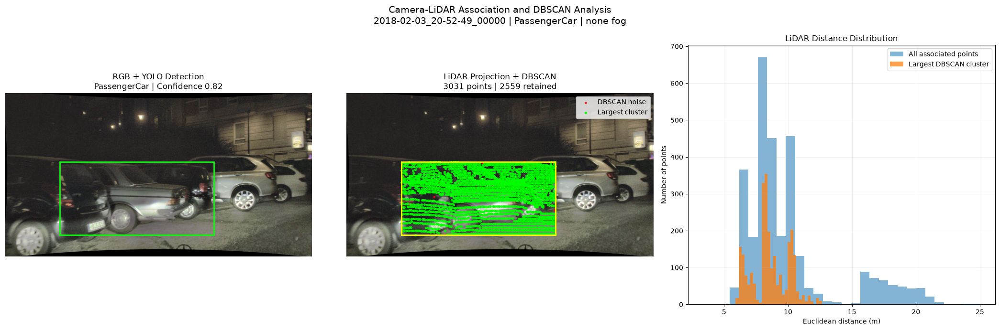

Saved: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples/case_0_2018-02-03_20-52-49_00000_dbscan.png

CASE 4: 2018-10-08_08-18-59_00370
Expected original points: 755
Reconstructed points: 755
Difference: 0
YOLO confidence: 0.968


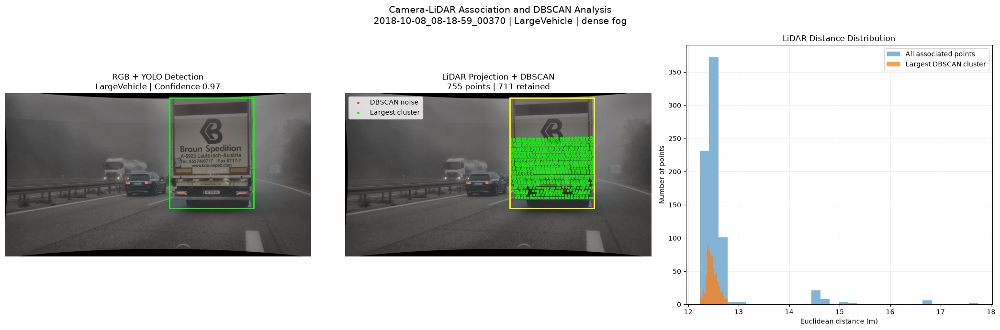

Saved: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples/case_4_2018-10-08_08-18-59_00370_dbscan.png

CASE 8: 2018-12-21_16-34-49_01000
Expected original points: 383
Reconstructed points: 383
Difference: 0
YOLO confidence: 0.935


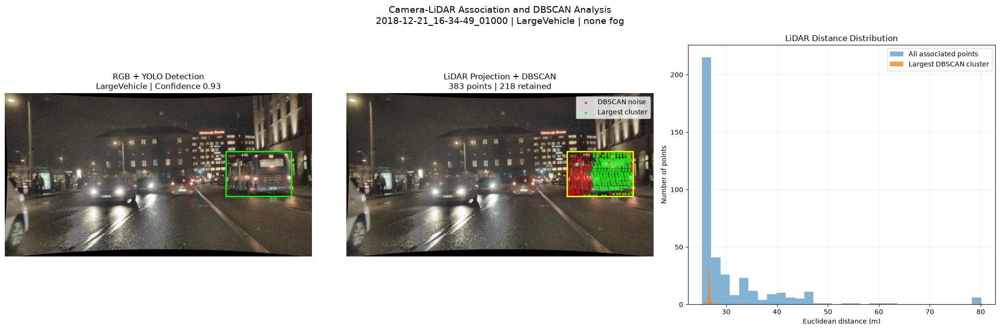

Saved: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples/case_8_2018-12-21_16-34-49_01000_dbscan.png

CASE 11: 2018-12-17_09-20-33_05900
Expected original points: 238
Reconstructed points: 238
Difference: 0
YOLO confidence: 0.811


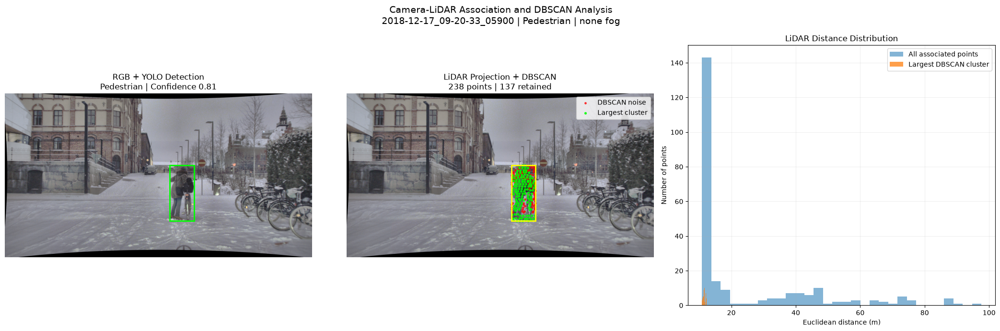

Saved: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples/case_11_2018-12-17_09-20-33_05900_dbscan.png

FINAL VERIFICATION
Expected figures: 4
Saved figures: 4
case_0_2018-02-03_20-52-49_00000_dbscan.png | 6795.1 KB
case_11_2018-12-17_09-20-33_05900_dbscan.png | 6394.6 KB
case_4_2018-10-08_08-18-59_00370_dbscan.png | 4674.0 KB
case_8_2018-12-21_16-34-49_01000_dbscan.png | 7291.6 KB

Summary CSV: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples/dbscan_visualization_summary.csv
Output folder: /home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_visual_examples


,case,frame_id,class,fog_condition,expected_points,reconstructed_points,point_difference,noise_points,largest_cluster_points,largest_cluster_pct,baseline_median_m,cluster_median_m,baseline_iqr_m,cluster_iqr_m,figure_path
0,0,2018-02-03_20-52-49_00000,PassengerCar,none,4108,3031,1077,42,2559,84.427582,8.688931,8.372463,2.299956,2.046407,/home/maritza/projects/autonomous_vehicle/outp...
1,4,2018-10-08_08-18-59_00370,LargeVehicle,dense,755,755,0,13,711,94.172185,12.469051,12.460225,0.170478,0.153919,/home/maritza/projects/autonomous_vehicle/outp...
2,8,2018-12-21_16-34-49_01000,LargeVehicle,none,383,383,0,149,218,56.919060,26.817019,26.631947,4.929205,0.247677,/home/maritza/projects/autonomous_vehicle/outp...
3,11,2018-12-17_09-20-33_05900,Pedestrian,none,238,238,0,101,137,57.563025,12.061005,11.526909,24.101616,0.391704,/home/maritza/projects/autonomous_vehicle/outp...


In [48]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from sklearn.cluster import DBSCAN
from ultralytics import YOLO

# ==================================================
# 1. CONFIGURATION
# ==================================================

SELECTED_CASES = [0, 4, 8, 11]

VISUALIZATION_DIR = OUTPUT_DIR / "dbscan_visual_examples"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODEL_PATH))

visualization_summaries = []

# ==================================================
# 2. PROCESS FOUR REPRESENTATIVE CASES
# ==================================================

for case_number in SELECTED_CASES:

    case = dbscan_results.iloc[case_number]

    frame_id = case["frame_id"]
    target_class = case["class"]
    expected_points = int(case["n_points"])
    fog_condition = case["fog_condition"]

    print("\n" + "=" * 65)
    print(f"CASE {case_number}: {frame_id}")
    print("=" * 65)

    # Load RGB
    rgb_path = RGB_DIR / f"{frame_id}.png"
    bgr = cv2.imread(str(rgb_path))

    if bgr is None:
        print("ERROR: RGB image not found.")
        continue

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # Load LiDAR
    lidar_path = LIDAR_DIR / f"{frame_id}.bin"

    if not lidar_path.exists():
        print("ERROR: LiDAR file not found.")
        continue

    lidar_data = np.fromfile(
        lidar_path,
        dtype=np.float32
    ).reshape(-1, 5)

    frame_xyz = lidar_data[:, :3]

    # Project LiDAR
    projection = project_lidar_points(
        frame_xyz,
        VTC,
        rgb.shape
    )

    # YOLO inference
    prediction = model.predict(
        source=rgb,
        conf=0.25,
        iou=0.5,
        verbose=False
    )[0]

    detections = []

    for box in prediction.boxes:

        class_id = int(box.cls[0].item())

        detections.append({
            "xyxy": box.xyxy[0].cpu().numpy(),
            "class_name": model.names[class_id],
            "confidence": float(box.conf[0].item())
        })

    # Associate LiDAR points
    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=3
    )

    # Find detections of the expected class
    candidates = []

    for det, assoc in zip(detections, associations):

        indices = np.asarray(
            assoc["associated_original_indices"]
        )

        if det["class_name"] == target_class:

            candidates.append({
                "detection": det,
                "association": assoc,
                "indices": indices,
                "point_difference": abs(
                    len(indices) - expected_points
                )
            })

    if not candidates:
        print(f"WARNING: No {target_class} detection found.")
        continue

    # Select candidate with closest point count
    selected = min(
        candidates,
        key=lambda item: item["point_difference"]
    )

    det = selected["detection"]
    assoc = selected["association"]
    point_indices = selected["indices"]

    print("Expected original points:", expected_points)
    print("Reconstructed points:", len(point_indices))
    print("Difference:", selected["point_difference"])
    print("YOLO confidence:", round(det["confidence"], 3))

    # Recover XYZ
    associated_xyz = frame_xyz[point_indices]

    # Apply DBSCAN using original parameters
    labels = DBSCAN(
        eps=DBSCAN_EPS,
        min_samples=DBSCAN_MIN_SAMPLES
    ).fit_predict(associated_xyz)

    valid_labels = [
        label for label in np.unique(labels)
        if label != -1
    ]

    if not valid_labels:
        print("WARNING: No valid DBSCAN cluster.")
        continue

    largest_label = max(
        valid_labels,
        key=lambda label: np.sum(labels == label)
    )

    cluster_mask = labels == largest_label
    noise_mask = labels == -1

    # Euclidean distances
    baseline_ranges = np.linalg.norm(
        associated_xyz,
        axis=1
    )

    cluster_ranges = baseline_ranges[cluster_mask]

    # Recover projected pixels
    projected_indices = projection["original_indices"]

    projected_mask = np.isin(
        projected_indices,
        point_indices
    )

    case_u = projection["u"][projected_mask]
    case_v = projection["v"][projected_mask]

    index_to_position = {
        idx: pos for pos, idx in enumerate(point_indices)
    }

    case_labels = np.array([
        labels[index_to_position[idx]]
        for idx in projected_indices[projected_mask]
    ])

    # Bounding box
    x1, y1, x2, y2 = det["xyxy"]

    # ==================================================
    # 3. VISUALIZATION
    # ==================================================

    fig, axes = plt.subplots(
        1, 3,
        figsize=(21, 7)
    )

    # Panel A: RGB + YOLO
    axes[0].imshow(rgb)

    axes[0].add_patch(
        plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )
    )

    axes[0].set_title(
        f"RGB + YOLO Detection\n"
        f"{target_class} | Confidence {det['confidence']:.2f}"
    )

    axes[0].axis("off")

    # Panel B: LiDAR + DBSCAN
    axes[1].imshow(rgb)

    projected_noise = case_labels == -1
    projected_cluster = case_labels == largest_label

    axes[1].scatter(
        case_u[projected_noise],
        case_v[projected_noise],
        s=6,
        c="red",
        label="DBSCAN noise",
        alpha=0.7
    )

    axes[1].scatter(
        case_u[projected_cluster],
        case_v[projected_cluster],
        s=8,
        c="lime",
        label="Largest cluster",
        alpha=0.8
    )

    axes[1].add_patch(
        plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="yellow",
            linewidth=2
        )
    )

    axes[1].set_title(
        f"LiDAR Projection + DBSCAN\n"
        f"{len(associated_xyz)} points | "
        f"{np.sum(cluster_mask)} retained"
    )

    axes[1].legend()
    axes[1].axis("off")

    # Panel C: Distance distributions
    axes[2].hist(
        baseline_ranges,
        bins=30,
        alpha=0.55,
        label="All associated points"
    )

    axes[2].hist(
        cluster_ranges,
        bins=30,
        alpha=0.75,
        label="Largest DBSCAN cluster"
    )

    axes[2].set_title("LiDAR Distance Distribution")
    axes[2].set_xlabel("Euclidean distance (m)")
    axes[2].set_ylabel("Number of points")
    axes[2].legend()
    axes[2].grid(alpha=0.2)

    fig.suptitle(
        f"Camera-LiDAR Association and DBSCAN Analysis\n"
        f"{frame_id} | {target_class} | {fog_condition} fog",
        fontsize=14
    )

    plt.tight_layout()

    # ==================================================
    # 4. SAVE FIGURE
    # ==================================================

    output_path = (
        VISUALIZATION_DIR /
        f"case_{case_number}_{frame_id}_dbscan.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

    # Save quantitative summary
    visualization_summaries.append({
        "case": case_number,
        "frame_id": frame_id,
        "class": target_class,
        "fog_condition": fog_condition,
        "expected_points": expected_points,
        "reconstructed_points": len(point_indices),
        "point_difference": selected["point_difference"],
        "noise_points": int(np.sum(noise_mask)),
        "largest_cluster_points": int(np.sum(cluster_mask)),
        "largest_cluster_pct": (
            np.sum(cluster_mask) / len(labels) * 100
        ),
        "baseline_median_m": np.median(baseline_ranges),
        "cluster_median_m": np.median(cluster_ranges),
        "baseline_iqr_m": (
            np.percentile(baseline_ranges, 75)
            - np.percentile(baseline_ranges, 25)
        ),
        "cluster_iqr_m": (
            np.percentile(cluster_ranges, 75)
            - np.percentile(cluster_ranges, 25)
        ),
        "figure_path": str(output_path)
    })


# ==================================================
# 5. SAVE SUMMARY AND VERIFY
# ==================================================

visualization_summary_df = pd.DataFrame(
    visualization_summaries
)

summary_path = (
    VISUALIZATION_DIR /
    "dbscan_visualization_summary.csv"
)

visualization_summary_df.to_csv(
    summary_path,
    index=False
)

saved_figures = list(
    VISUALIZATION_DIR.glob("case_*_dbscan.png")
)

print("\n" + "=" * 65)
print("FINAL VERIFICATION")
print("=" * 65)

print("Expected figures:", len(SELECTED_CASES))
print("Saved figures:", len(saved_figures))

for path in sorted(saved_figures):
    print(f"{path.name} | {path.stat().st_size / 1024:.1f} KB")

print("\nSummary CSV:", summary_path)
print("Output folder:", VISUALIZATION_DIR)

display(visualization_summary_df)



In [49]:

# ==================================================
# DBSCAN QUANTITATIVE EVALUATION
# Step 1: Inspect existing data
# ==================================================

print("FUSION RESULTS")
print("==============================")
print("Shape:", fusion_results.shape)
print("Columns:")
print(fusion_results.columns.tolist())

display(fusion_results.head(5))

print("\nDBSCAN RESULTS")
print("==============================")
print("Shape:", dbscan_results.shape)
print("Columns:")
print(dbscan_results.columns.tolist())

display(dbscan_results.head(5))

print("\nFRAME SUMMARY")
print("==============================")
print("Shape:", frame_results.shape)
print("Columns:")
print(frame_results.columns.tolist())

display(frame_results.head(5))

print("\nREPRESENTATIVE CASES")
print("==============================")
display(representative_cases.head(5))


FUSION RESULTS
Shape: (570, 12)
Columns:
['frame_id', 'fog_condition', 'precipitation_condition', 'daytime_condition', 'road_condition', 'class', 'yolo_confidence', 'lidar_points_in_box', 'median_lidar_range', 'range_q25', 'range_q75', 'range_status']


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.835323,44,23.854698,23.418319,31.593090,estimated
1,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.771204,43,23.406321,23.292872,25.468864,estimated
2,2018-02-07_18-26-13_00600,dense,none,night,full_snow,Pedestrian,0.853929,264,9.874117,9.733761,13.954299,estimated
3,2018-02-07_18-26-13_00600,dense,none,night,full_snow,PassengerCar,0.532352,29,73.878593,67.007301,76.429260,estimated
4,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,RidableVehicle,0.752459,27,30.174017,29.772502,30.280407,estimated



DBSCAN RESULTS
Shape: (12, 15)
Columns:
['frame_id', 'class', 'fog_condition', 'n_points', 'n_clusters', 'noise_points', 'noise_pct', 'baseline_median_m', 'baseline_iqr_m', 'largest_cluster_points', 'largest_cluster_pct', 'cluster_median_m', 'cluster_iqr_m', 'cluster_p90_p10_m', 'median_difference_m']


,frame_id,class,fog_condition,n_points,n_clusters,noise_points,noise_pct,baseline_median_m,baseline_iqr_m,largest_cluster_points,largest_cluster_pct,cluster_median_m,cluster_iqr_m,cluster_p90_p10_m,median_difference_m
0,2018-02-03_20-52-49_00000,PassengerCar,none,4108,7,53,1.290166,8.421619,3.374498,3362,81.840312,8.173178,2.697496,4.022543,-0.248442
1,2018-02-03_20-52-49_00000,PassengerCar,none,4075,7,37,0.907975,8.075549,3.655087,3226,79.165644,7.238268,1.807894,2.909851,-0.837281
2,2018-02-12_16-58-59_00280,PassengerCar,dense,1043,5,167,16.011505,13.012220,1.661381,776,74.400767,12.925740,0.286940,0.595644,-0.086480
3,2018-02-12_15-52-57_00200,PassengerCar,light,898,5,42,4.677060,11.650476,12.132954,615,68.485523,11.510912,0.291764,0.517482,-0.139565
4,2018-10-08_08-18-59_00370,LargeVehicle,dense,755,2,13,1.721854,12.469051,0.170478,711,94.172185,12.460225,0.153919,0.282518,-0.008826



FRAME SUMMARY
Shape: (120, 10)
Columns:
['frame_id', 'fog_condition', 'precipitation_condition', 'daytime_condition', 'road_condition', 'n_lidar_input', 'n_lidar_projected', 'n_yolo_detections', 'n_detections_with_range', 'n_detections_without_range']


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,n_lidar_input,n_lidar_projected,n_yolo_detections,n_detections_with_range,n_detections_without_range
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,55146,4536,2,2,0
1,2018-02-07_18-26-13_00600,dense,none,night,full_snow,55125,4500,2,2,0
2,2018-02-12_09-17-17_00430,dense,heavy_snow,day,partial_snow,55304,3694,0,0,0
3,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,55229,4436,1,1,0
4,2018-02-12_16-58-59_00130,dense,heavy_snow,night,full_snow,55036,4446,6,5,1



REPRESENTATIVE CASES


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,2018-02-03_20-52-49_00000,none,rain,night,dry,PassengerCar,0.622270,4108,8.421619,7.050963,10.425461,estimated
1,2018-02-03_20-52-49_00000,none,rain,night,dry,PassengerCar,0.411128,4075,8.075549,6.597579,10.252666,estimated
2,2018-02-12_16-58-59_00280,dense,heavy_snow,night,full_snow,PassengerCar,0.931706,1043,13.012220,12.832680,14.494061,estimated
3,2018-02-12_15-52-57_00200,light,heavy_snow,day,full_snow,PassengerCar,0.894287,898,11.650476,11.431017,23.563971,estimated
4,2018-10-08_08-18-59_00370,dense,none,day,dry,LargeVehicle,0.967901,755,12.469051,12.400309,12.570786,estimated


In [50]:
# ============================================================
# STAGE 4C - QUANTITATIVE DBSCAN EVALUATION
# STEP 1: Inspect the 120-frame dataset
# ============================================================

print("=" * 65)
print("120-FRAME FUSION DATA")
print("=" * 65)

print("\nDetection-level results:")
print("Shape:", fusion_results.shape)
print("Columns:", fusion_results.columns.tolist())

display(fusion_results.head(5))

print("\nFrame-level results:")
print("Shape:", frame_results.shape)
print("Columns:", frame_results.columns.tolist())

display(frame_results.head(5))

print("\nSampling manifest:")
manifest_path = (
    OUTPUT_DIR / "stage4_120_frame_sampling_manifest.csv"
)

if manifest_path.exists():
    sampling_manifest = pd.read_csv(manifest_path)

    print("Shape:", sampling_manifest.shape)
    print("Columns:", sampling_manifest.columns.tolist())
    display(sampling_manifest.head(5))
else:
    print("Sampling manifest not found at:", manifest_path)

print("\nExisting DBSCAN parameters:")
print("EPS:", DBSCAN_EPS)
print("MIN_SAMPLES:", DBSCAN_MIN_SAMPLES)

print("\nOutput directory:")
print(OUTPUT_DIR)


120-FRAME FUSION DATA

Detection-level results:
Shape: (570, 12)
Columns: ['frame_id', 'fog_condition', 'precipitation_condition', 'daytime_condition', 'road_condition', 'class', 'yolo_confidence', 'lidar_points_in_box', 'median_lidar_range', 'range_q25', 'range_q75', 'range_status']


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,class,yolo_confidence,lidar_points_in_box,median_lidar_range,range_q25,range_q75,range_status
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.835323,44,23.854698,23.418319,31.593090,estimated
1,2018-02-07_18-26-13_00500,dense,none,night,full_snow,Pedestrian,0.771204,43,23.406321,23.292872,25.468864,estimated
2,2018-02-07_18-26-13_00600,dense,none,night,full_snow,Pedestrian,0.853929,264,9.874117,9.733761,13.954299,estimated
3,2018-02-07_18-26-13_00600,dense,none,night,full_snow,PassengerCar,0.532352,29,73.878593,67.007301,76.429260,estimated
4,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,RidableVehicle,0.752459,27,30.174017,29.772502,30.280407,estimated



Frame-level results:
Shape: (120, 10)
Columns: ['frame_id', 'fog_condition', 'precipitation_condition', 'daytime_condition', 'road_condition', 'n_lidar_input', 'n_lidar_projected', 'n_yolo_detections', 'n_detections_with_range', 'n_detections_without_range']


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition,n_lidar_input,n_lidar_projected,n_yolo_detections,n_detections_with_range,n_detections_without_range
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow,55146,4536,2,2,0
1,2018-02-07_18-26-13_00600,dense,none,night,full_snow,55125,4500,2,2,0
2,2018-02-12_09-17-17_00430,dense,heavy_snow,day,partial_snow,55304,3694,0,0,0
3,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow,55229,4436,1,1,0
4,2018-02-12_16-58-59_00130,dense,heavy_snow,night,full_snow,55036,4446,6,5,1



Sampling manifest:
Shape: (120, 5)
Columns: ['frame_id', 'fog_condition', 'precipitation_condition', 'daytime_condition', 'road_condition']


,frame_id,fog_condition,precipitation_condition,daytime_condition,road_condition
0,2018-02-07_18-26-13_00500,dense,none,night,full_snow
1,2018-02-07_18-26-13_00600,dense,none,night,full_snow
2,2018-02-12_09-17-17_00430,dense,heavy_snow,day,partial_snow
3,2018-02-12_16-02-49_00040,dense,heavy_snow,day,full_snow
4,2018-02-12_16-58-59_00130,dense,heavy_snow,night,full_snow



Existing DBSCAN parameters:
EPS: 0.8
MIN_SAMPLES: 10

Output directory:
/home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion


In [51]:
# Inspect the structure of existing fusion associations

print("Number of stored frame associations:", len(frame_associations))

if len(frame_associations) > 0:

    first_frame = frame_associations[0]

    print("\nFirst frame association type:")
    print(type(first_frame))

    if isinstance(first_frame, dict):
        print("Keys:", first_frame.keys())

        for key, value in first_frame.items():
            print(
                key,
                "| type:", type(value).__name__,
                "| shape:", getattr(value, "shape", None)
            )

    elif isinstance(first_frame, list):
        print("Number of detections:", len(first_frame))

        if len(first_frame) > 0:
            print("First detection keys:", first_frame[0].keys())

            for key, value in first_frame[0].items():
                print(
                    key,
                    "| type:", type(value).__name__,
                    "| shape:", getattr(value, "shape", None)
                )


Number of stored frame associations: 3

First frame association type:
<class 'dict'>
Keys: dict_keys(['detection_id', 'class_name', 'confidence', 'bbox_xyxy', 'n_lidar_points', 'median_lidar_range', 'range_q25', 'range_q75', 'status', 'associated_original_indices'])
detection_id | type: int | shape: None
class_name | type: str | shape: None
confidence | type: float | shape: None
bbox_xyxy | type: ndarray | shape: (4,)
n_lidar_points | type: int | shape: None
median_lidar_range | type: float | shape: None
range_q25 | type: float | shape: None
range_q75 | type: float | shape: None
status | type: str | shape: None
associated_original_indices | type: ndarray | shape: (53,)


In [52]:
# ============================================================
# STAGE 4C - DBSCAN EVALUATION ON 120 FRAMES
# ============================================================

import numpy as np
import pandas as pd
import cv2
import gc

from pathlib import Path
from sklearn.cluster import DBSCAN
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DBSCAN_OUTPUT_DIR = OUTPUT_DIR / "dbscan_120_frame_evaluation"
DBSCAN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DETECTION_OUTPUT = (
    DBSCAN_OUTPUT_DIR /
    "stage4_120_frame_dbscan_detection_results.csv"
)

FRAME_OUTPUT = (
    DBSCAN_OUTPUT_DIR /
    "stage4_120_frame_dbscan_frame_results.csv"
)

SUMMARY_OUTPUT = (
    DBSCAN_OUTPUT_DIR /
    "stage4_120_frame_dbscan_summary.csv"
)

# Load sampling manifest
sampling_manifest = pd.read_csv(
    OUTPUT_DIR / "stage4_120_frame_sampling_manifest.csv"
)

# Load existing model (no retraining)
model = YOLO(str(MODEL_PATH))

# ------------------------------------------------------------
# 2. Resume support
# ------------------------------------------------------------

if DETECTION_OUTPUT.exists():
    existing_results = pd.read_csv(DETECTION_OUTPUT)
    processed_frames = set(existing_results["frame_id"].unique())
    detection_rows = existing_results.to_dict("records")
else:
    processed_frames = set()
    detection_rows = []

if FRAME_OUTPUT.exists():
    existing_frame_results = pd.read_csv(FRAME_OUTPUT)
    processed_frame_ids = set(existing_frame_results["frame_id"])
    frame_rows = existing_frame_results.to_dict("records")
else:
    processed_frame_ids = set()
    frame_rows = []

print("Frames in manifest:", len(sampling_manifest))
print("Already processed:", len(processed_frame_ids))

# ------------------------------------------------------------
# 3. Process frames
# ------------------------------------------------------------

for frame_number, metadata in sampling_manifest.iterrows():

    frame_id = metadata["frame_id"]

    if frame_id in processed_frame_ids:
        continue

    print(
        f"\nProcessing {frame_number + 1}/"
        f"{len(sampling_manifest)}: {frame_id}"
    )

    rgb_path = RGB_DIR / f"{frame_id}.png"
    lidar_path = LIDAR_DIR / f"{frame_id}.bin"

    if not rgb_path.exists() or not lidar_path.exists():
        print("Missing RGB or LiDAR file. Skipping.")
        continue

    # Load RGB
    bgr = cv2.imread(str(rgb_path))

    if bgr is None:
        print("Could not read RGB image. Skipping.")
        continue

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    # Load LiDAR
    lidar_data = np.fromfile(
        lidar_path,
        dtype=np.float32
    ).reshape(-1, 5)

    frame_xyz = lidar_data[:, :3]

    # Project LiDAR
    projection = project_lidar_points(
        frame_xyz,
        VTC,
        rgb.shape
    )

    # YOLO inference
    prediction = model.predict(
        source=rgb,
        conf=0.25,
        iou=0.5,
        verbose=False
    )[0]

    detections = []

    for box in prediction.boxes:

        class_id = int(box.cls[0].item())

        detections.append({
            "xyxy": box.xyxy[0].cpu().numpy(),
            "class_name": model.names[class_id],
            "confidence": float(box.conf[0].item())
        })

    # Associate projected LiDAR points
    associations = associate_lidar_with_detections(
        detections,
        projection,
        min_points=3
    )

    # Frame-level summary
    frame_dbscan_count = 0

    for det, assoc in zip(detections, associations):

        point_indices = np.asarray(
            assoc["associated_original_indices"],
            dtype=int
        )

        n_points = len(point_indices)

        # Metadata for each detection
        row = {
            "frame_id": frame_id,
            "fog_condition": metadata["fog_condition"],
            "precipitation_condition": metadata["precipitation_condition"],
            "daytime_condition": metadata["daytime_condition"],
            "road_condition": metadata["road_condition"],
            "class": det["class_name"],
            "yolo_confidence": det["confidence"],
            "n_points": n_points,
            "dbscan_status": "not_evaluated"
        }

        if n_points < DBSCAN_MIN_SAMPLES:
            row.update({
                "baseline_median_m": np.nan,
                "baseline_iqr_m": np.nan,
                "baseline_p90_p10_m": np.nan,
                "noise_points": np.nan,
                "noise_pct": np.nan,
                "n_clusters": 0,
                "largest_cluster_points": 0,
                "largest_cluster_pct": np.nan,
                "cluster_median_m": np.nan,
                "cluster_iqr_m": np.nan,
                "cluster_p90_p10_m": np.nan,
                "median_difference_m": np.nan,
                "iqr_reduction_pct": np.nan
            })

            detection_rows.append(row)
            continue

        # Recover original XYZ coordinates
        associated_xyz = frame_xyz[point_indices]

        # Euclidean LiDAR range
        ranges = np.linalg.norm(
            associated_xyz,
            axis=1
        )

        # Baseline metrics
        baseline_median = np.median(ranges)

        baseline_q25 = np.percentile(ranges, 25)
        baseline_q75 = np.percentile(ranges, 75)

        baseline_iqr = baseline_q75 - baseline_q25

        baseline_spread = (
            np.percentile(ranges, 90)
            - np.percentile(ranges, 10)
        )

        # DBSCAN
        labels = DBSCAN(
            eps=DBSCAN_EPS,
            min_samples=DBSCAN_MIN_SAMPLES
        ).fit_predict(associated_xyz)

        noise_mask = labels == -1
        valid_labels = [
            label for label in np.unique(labels)
            if label != -1
        ]

        noise_points = int(np.sum(noise_mask))
        noise_pct = noise_points / n_points * 100

        if not valid_labels:

            row.update({
                "baseline_median_m": baseline_median,
                "baseline_iqr_m": baseline_iqr,
                "baseline_p90_p10_m": baseline_spread,
                "noise_points": noise_points,
                "noise_pct": noise_pct,
                "n_clusters": 0,
                "largest_cluster_points": 0,
                "largest_cluster_pct": 0.0,
                "cluster_median_m": np.nan,
                "cluster_iqr_m": np.nan,
                "cluster_p90_p10_m": np.nan,
                "median_difference_m": np.nan,
                "iqr_reduction_pct": np.nan,
                "dbscan_status": "no_valid_cluster"
            })

            detection_rows.append(row)
            continue

        # Largest cluster
        largest_label = max(
            valid_labels,
            key=lambda label: np.sum(labels == label)
        )

        cluster_mask = labels == largest_label
        cluster_ranges = ranges[cluster_mask]

        cluster_median = np.median(cluster_ranges)

        cluster_iqr = (
            np.percentile(cluster_ranges, 75)
            - np.percentile(cluster_ranges, 25)
        )

        cluster_spread = (
            np.percentile(cluster_ranges, 90)
            - np.percentile(cluster_ranges, 10)
        )

        largest_cluster_points = int(np.sum(cluster_mask))

        largest_cluster_pct = (
            largest_cluster_points / n_points * 100
        )

        # Comparison metrics
        median_difference = cluster_median - baseline_median

        if baseline_iqr > 0:
            iqr_reduction = (
                1 - cluster_iqr / baseline_iqr
            ) * 100
        else:
            iqr_reduction = np.nan

        row.update({
            "baseline_median_m": baseline_median,
            "baseline_iqr_m": baseline_iqr,
            "baseline_p90_p10_m": baseline_spread,
            "noise_points": noise_points,
            "noise_pct": noise_pct,
            "n_clusters": len(valid_labels),
            "largest_cluster_points": largest_cluster_points,
            "largest_cluster_pct": largest_cluster_pct,
            "cluster_median_m": cluster_median,
            "cluster_iqr_m": cluster_iqr,
            "cluster_p90_p10_m": cluster_spread,
            "median_difference_m": median_difference,
            "iqr_reduction_pct": iqr_reduction,
            "dbscan_status": "valid_cluster"
        })

        detection_rows.append(row)
        frame_dbscan_count += 1

    # Frame summary
    frame_rows.append({
        "frame_id": frame_id,
        "fog_condition": metadata["fog_condition"],
        "precipitation_condition": metadata["precipitation_condition"],
        "daytime_condition": metadata["daytime_condition"],
        "road_condition": metadata["road_condition"],
        "n_yolo_detections": len(detections),
        "n_dbscan_evaluated": frame_dbscan_count
    })

    processed_frame_ids.add(frame_id)

    # Save incrementally after every frame
    pd.DataFrame(detection_rows).to_csv(
        DETECTION_OUTPUT,
        index=False
    )

    pd.DataFrame(frame_rows).to_csv(
        FRAME_OUTPUT,
        index=False
    )

    print(
        "Detections:", len(detections),
        "| DBSCAN evaluated:", frame_dbscan_count
    )

    del frame_xyz, lidar_data, projection
    gc.collect()

print("\nPROCESSING COMPLETED")
print("Detection results:", DETECTION_OUTPUT)
print("Frame results:", FRAME_OUTPUT)
print("Processed frames:", len(processed_frame_ids))


Frames in manifest: 120
Already processed: 0

Processing 1/120: 2018-02-07_18-26-13_00500
Detections: 2 | DBSCAN evaluated: 2

Processing 2/120: 2018-02-07_18-26-13_00600
Detections: 2 | DBSCAN evaluated: 1

Processing 3/120: 2018-02-12_09-17-17_00430
Detections: 0 | DBSCAN evaluated: 0

Processing 4/120: 2018-02-12_16-02-49_00040
Detections: 1 | DBSCAN evaluated: 1

Processing 5/120: 2018-02-12_16-58-59_00130
Detections: 6 | DBSCAN evaluated: 2

Processing 6/120: 2018-02-12_16-58-59_00280
Detections: 4 | DBSCAN evaluated: 4

Processing 7/120: 2018-10-08_08-10-40_02530
Detections: 2 | DBSCAN evaluated: 1

Processing 8/120: 2018-10-08_08-10-40_02640
Detections: 1 | DBSCAN evaluated: 0

Processing 9/120: 2018-10-08_08-10-40_02730
Detections: 1 | DBSCAN evaluated: 0

Processing 10/120: 2018-10-08_08-10-40_03020
Detections: 4 | DBSCAN evaluated: 2

Processing 11/120: 2018-10-08_08-18-59_00370
Detections: 2 | DBSCAN evaluated: 2

Processing 12/120: 2018-10-08_08-18-59_03700
Detections: 3 | 

In [53]:
# Verify evaluation coverage

dbscan_detection_results = pd.read_csv(DETECTION_OUTPUT)
dbscan_frame_results = pd.read_csv(FRAME_OUTPUT)

print("Processed frames:", dbscan_frame_results["frame_id"].nunique())
print("Detection records:", len(dbscan_detection_results))

print("\nDBSCAN status:")
display(
    dbscan_detection_results["dbscan_status"]
    .value_counts(dropna=False)
)

print("\nFrames by fog condition:")
display(
    dbscan_frame_results["fog_condition"]
    .value_counts()
)

print("\nDetection classes:")
display(
    dbscan_detection_results["class"]
    .value_counts()
)


Processed frames: 120
Detection records: 525

DBSCAN status:


dbscan_status
valid_cluster       263
not_evaluated       165
no_valid_cluster     97
Name: count, dtype: int64


Frames by fog condition:


fog_condition
dense    40
light    40
none     40
Name: count, dtype: int64


Detection classes:


class
PassengerCar      316
Pedestrian        176
LargeVehicle       31
RidableVehicle      2
Name: count, dtype: int64

DBSCAN STATUS DISTRIBUTION


,dbscan_status,detections,percentage
0,no_valid_cluster,97,18.48
1,not_evaluated,165,31.43
2,valid_cluster,263,50.10



Valid DBSCAN detections: 263

OVERALL METRICS


,metric,value
0,Valid DBSCAN detections,263.000
1,Mean point retention (%),61.960
2,Median point retention (%),62.745
3,Mean noise (%),30.257
4,Mean baseline IQR (m),6.150
5,Mean cluster IQR (m),0.478
6,Median baseline IQR (m),2.754
7,Median cluster IQR (m),0.242
8,Mean IQR reduction (%),70.447
9,Median IQR reduction (%),84.803



RESULTS BY FOG CONDITION


,fog_condition,detections,mean_retention_pct,median_retention_pct,mean_noise_pct,baseline_iqr_median,cluster_iqr_median,mean_iqr_reduction_pct,median_iqr_reduction_pct,mean_distance_change_m
0,dense,52,67.791,68.627,21.232,1.357,0.161,63.932,77.170,0.076
1,light,77,59.912,61.290,33.853,2.864,0.233,72.943,91.944,-0.717
2,none,134,60.875,61.551,31.692,3.245,0.282,71.541,87.563,-0.753



RESULTS BY OBJECT CLASS


,class,detections,mean_retention_pct,mean_noise_pct,baseline_iqr_median,cluster_iqr_median,median_iqr_reduction_pct,mean_distance_change_m
0,LargeVehicle,20,59.549,27.344,3.787,0.231,85.184,-0.733
1,PassengerCar,161,62.459,29.610,2.769,0.356,80.844,-0.795
2,Pedestrian,80,61.448,32.204,2.372,0.170,92.758,-0.114
3,RidableVehicle,2,66.491,33.509,5.167,0.266,86.405,-0.128



RESULTS BY CLASS AND FOG


,class,fog_condition,detections,mean_retention_pct,median_iqr_reduction_pct,baseline_iqr_median,cluster_iqr_median,mean_distance_change_m
0,LargeVehicle,dense,8,67.040,69.456,1.131,0.132,0.010
1,LargeVehicle,light,6,54.948,77.243,6.566,0.238,-1.975
2,LargeVehicle,none,6,54.161,91.421,4.109,0.244,-0.481
3,PassengerCar,dense,29,68.293,77.309,1.661,0.235,0.146
4,PassengerCar,light,52,61.430,80.129,2.435,0.369,-0.747
5,PassengerCar,none,80,61.012,81.904,3.306,0.428,-1.168
6,Pedestrian,dense,14,67.261,76.898,0.631,0.152,-0.028
7,Pedestrian,light,19,57.324,96.550,4.997,0.150,-0.236
8,Pedestrian,none,47,61.383,90.614,2.069,0.184,-0.090
9,RidableVehicle,dense,1,66.667,77.032,0.508,0.117,0.022


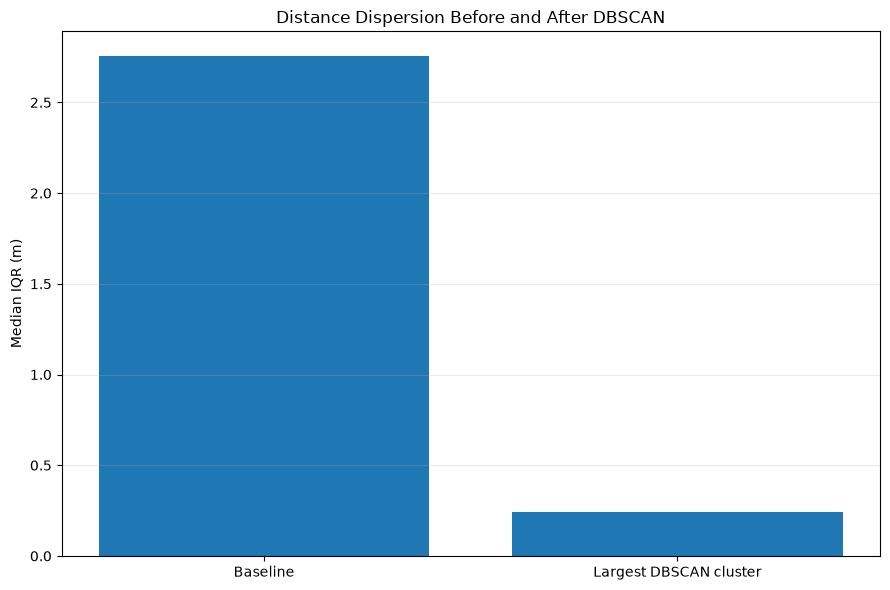

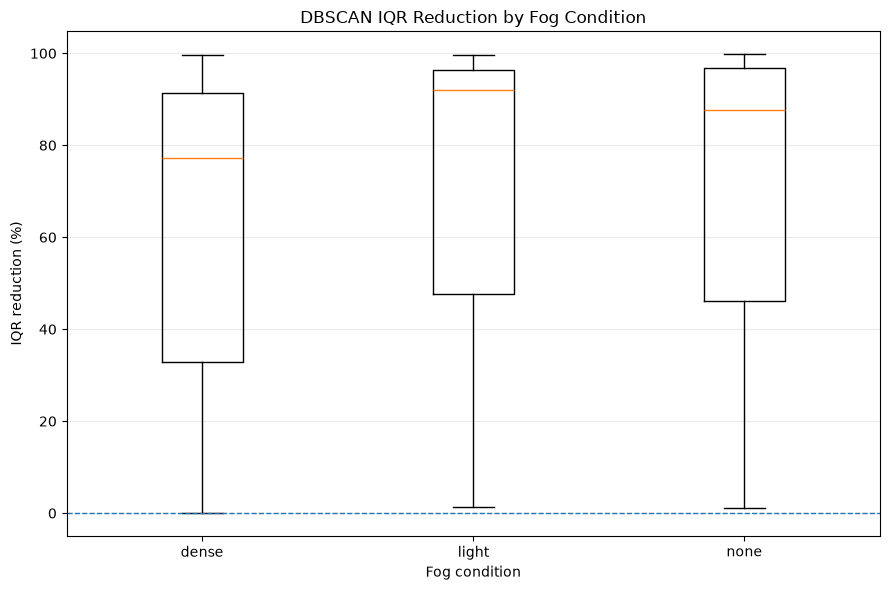

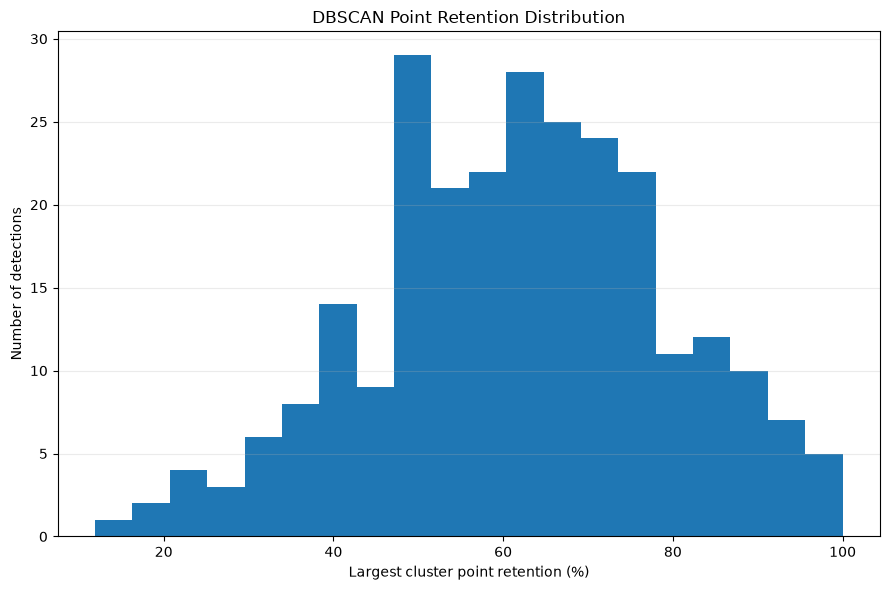


EVALUATION TABLES AND FIGURES SAVED
/home/maritza/projects/autonomous_vehicle/outputs/stage4_camera_lidar_fusion/dbscan_120_frame_evaluation


: 

In [ ]:
# ============================================================
# STAGE 4C - DBSCAN QUANTITATIVE ANALYSIS
# Step 2: Metrics, aggregation and plots
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load complete detection results
dbscan_detection_results = pd.read_csv(DETECTION_OUTPUT)

# Output paths
DBSCAN_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Status distribution
# ------------------------------------------------------------

status_summary = (
    dbscan_detection_results
    .groupby("dbscan_status")
    .size()
    .reset_index(name="detections")
)

status_summary["percentage"] = (
    status_summary["detections"]
    / len(dbscan_detection_results) * 100
)

print("DBSCAN STATUS DISTRIBUTION")
display(status_summary.round(2))

# ------------------------------------------------------------
# 2. Valid cluster results
# ------------------------------------------------------------

valid_results = dbscan_detection_results[
    dbscan_detection_results["dbscan_status"] == "valid_cluster"
].copy()

print("\nValid DBSCAN detections:", len(valid_results))

# Verify numeric columns
metric_columns = [
    "largest_cluster_pct",
    "noise_pct",
    "baseline_median_m",
    "cluster_median_m",
    "baseline_iqr_m",
    "cluster_iqr_m",
    "median_difference_m",
    "iqr_reduction_pct"
]

for col in metric_columns:
    valid_results[col] = pd.to_numeric(
        valid_results[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. Overall quantitative metrics
# ------------------------------------------------------------

overall_metrics = pd.DataFrame({
    "metric": [
        "Valid DBSCAN detections",
        "Mean point retention (%)",
        "Median point retention (%)",
        "Mean noise (%)",
        "Mean baseline IQR (m)",
        "Mean cluster IQR (m)",
        "Median baseline IQR (m)",
        "Median cluster IQR (m)",
        "Mean IQR reduction (%)",
        "Median IQR reduction (%)",
        "Mean median-distance difference (m)"
    ],
    "value": [
        len(valid_results),
        valid_results["largest_cluster_pct"].mean(),
        valid_results["largest_cluster_pct"].median(),
        valid_results["noise_pct"].mean(),
        valid_results["baseline_iqr_m"].mean(),
        valid_results["cluster_iqr_m"].mean(),
        valid_results["baseline_iqr_m"].median(),
        valid_results["cluster_iqr_m"].median(),
        valid_results["iqr_reduction_pct"].mean(),
        valid_results["iqr_reduction_pct"].median(),
        valid_results["median_difference_m"].mean()
    ]
})

print("\nOVERALL METRICS")
display(overall_metrics.round(3))

# ------------------------------------------------------------
# 4. Results by fog condition
# ------------------------------------------------------------

fog_summary = (
    valid_results
    .groupby("fog_condition")
    .agg(
        detections=("frame_id", "size"),
        mean_retention_pct=("largest_cluster_pct", "mean"),
        median_retention_pct=("largest_cluster_pct", "median"),
        mean_noise_pct=("noise_pct", "mean"),
        baseline_iqr_median=("baseline_iqr_m", "median"),
        cluster_iqr_median=("cluster_iqr_m", "median"),
        mean_iqr_reduction_pct=("iqr_reduction_pct", "mean"),
        median_iqr_reduction_pct=("iqr_reduction_pct", "median"),
        mean_distance_change_m=("median_difference_m", "mean")
    )
    .reset_index()
)

print("\nRESULTS BY FOG CONDITION")
display(fog_summary.round(3))

# ------------------------------------------------------------
# 5. Results by object class
# ------------------------------------------------------------

class_summary = (
    valid_results
    .groupby("class")
    .agg(
        detections=("frame_id", "size"),
        mean_retention_pct=("largest_cluster_pct", "mean"),
        mean_noise_pct=("noise_pct", "mean"),
        baseline_iqr_median=("baseline_iqr_m", "median"),
        cluster_iqr_median=("cluster_iqr_m", "median"),
        median_iqr_reduction_pct=("iqr_reduction_pct", "median"),
        mean_distance_change_m=("median_difference_m", "mean")
    )
    .reset_index()
)

print("\nRESULTS BY OBJECT CLASS")
display(class_summary.round(3))

# ------------------------------------------------------------
# 6. Results by class and fog condition
# ------------------------------------------------------------

class_fog_summary = (
    valid_results
    .groupby(["class", "fog_condition"])
    .agg(
        detections=("frame_id", "size"),
        mean_retention_pct=("largest_cluster_pct", "mean"),
        median_iqr_reduction_pct=("iqr_reduction_pct", "median"),
        baseline_iqr_median=("baseline_iqr_m", "median"),
        cluster_iqr_median=("cluster_iqr_m", "median"),
        mean_distance_change_m=("median_difference_m", "mean")
    )
    .reset_index()
)

print("\nRESULTS BY CLASS AND FOG")
display(class_fog_summary.round(3))

# ------------------------------------------------------------
# 7. Save tables
# ------------------------------------------------------------

status_summary.to_csv(
    DBSCAN_OUTPUT_DIR / "dbscan_status_summary.csv",
    index=False
)

overall_metrics.to_csv(
    DBSCAN_OUTPUT_DIR / "dbscan_overall_metrics.csv",
    index=False
)

fog_summary.to_csv(
    DBSCAN_OUTPUT_DIR / "dbscan_metrics_by_fog.csv",
    index=False
)

class_summary.to_csv(
    DBSCAN_OUTPUT_DIR / "dbscan_metrics_by_class.csv",
    index=False
)

class_fog_summary.to_csv(
    DBSCAN_OUTPUT_DIR / "dbscan_metrics_by_class_and_fog.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Visualization: IQR before vs after DBSCAN
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

labels = ["Baseline", "Largest DBSCAN cluster"]

medians = [
    valid_results["baseline_iqr_m"].median(),
    valid_results["cluster_iqr_m"].median()
]

ax.bar(labels, medians)
ax.set_ylabel("Median IQR (m)")
ax.set_title("Distance Dispersion Before and After DBSCAN")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    DBSCAN_OUTPUT_DIR / "dbscan_iqr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Visualization: IQR reduction by fog
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

fog_order = ["dense", "light", "none"]

plot_data = [
    valid_results.loc[
        valid_results["fog_condition"] == fog,
        "iqr_reduction_pct"
    ].dropna().values
    for fog in fog_order
]

ax.boxplot(
    plot_data,
    tick_labels=fog_order,
    showfliers=False
)

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("Fog condition")
ax.set_ylabel("IQR reduction (%)")
ax.set_title("DBSCAN IQR Reduction by Fog Condition")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    DBSCAN_OUTPUT_DIR / "dbscan_iqr_reduction_by_fog.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Visualization: Point retention
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    valid_results["largest_cluster_pct"].dropna(),
    bins=20
)

ax.set_xlabel("Largest cluster point retention (%)")
ax.set_ylabel("Number of detections")
ax.set_title("DBSCAN Point Retention Distribution")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

fig.savefig(
    DBSCAN_OUTPUT_DIR / "dbscan_point_retention_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nEVALUATION TABLES AND FIGURES SAVED")
print(DBSCAN_OUTPUT_DIR)
